# Netflix Google Play Reviews: SWOT Classification


## 1. Setup


In [1]:
%pip install -q transformers==4.57.1 datasets==3.6.0 accelerate==1.10.1 bitsandbytes==0.48.1 langdetect emoji rapidfuzz spacy==3.8.7 wordcloud captum lime shap safetensors kagglehub
%pip install -q https://github.com/explosion/spacy-models/releases/download/en_core_web_sm-3.8.0/en_core_web_sm-3.8.0-py3-none-any.whl


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 38.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 73.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 22.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 374.9/374.9 kB 16.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.1/60.1 MB 27.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.9/33.9 MB 57.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 87.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 20.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 31.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.1/183.1 kB 7.4 MB/s eta 0:00:00


In [2]:
import os
import re
import gc
import json
import shutil
import hashlib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import kagglehub
import emoji
import spacy
import shap

from pathlib import Path
from datetime import datetime, timezone
from collections import defaultdict
from itertools import combinations
from tqdm.auto import tqdm
from langdetect import DetectorFactory, detect
from langdetect.lang_detect_exception import LangDetectException
from rapidfuzz import fuzz, process
from datasets import Dataset
from transformers import (
    AutoModelForCausalLM,
    AutoModelForSequenceClassification,
    AutoTokenizer,
    BitsAndBytesConfig,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
    Trainer,
    TrainerCallback,
    TrainingArguments,
    set_seed,
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from scipy.special import softmax
from scipy.integrate import trapezoid
from captum.attr import LayerIntegratedGradients
from lime.lime_text import LimeTextExplainer
from wordcloud import STOPWORDS, WordCloud


In [3]:
os.environ["TOKENIZERS_PARALLELISM"] = "false"
SEED = 42
set_seed(SEED)
SWOT_LABELS = ["Strength", "Weakness", "Opportunity", "Threat"]

if not torch.cuda.is_available():
    raise RuntimeError("Enable a Kaggle GPU accelerator before running this notebook.")

SILVER_INPUT = Path("/kaggle/input/datasets/anastasiapolitidou/llm-labeled-with-source/silver_labeled_with_source.csv")
working_cache = Path("/kaggle/working/silver_labeled_with_source.csv")
if SILVER_INPUT.is_file():
    LLM_CACHE = str(SILVER_INPUT)
elif working_cache.is_file():
    LLM_CACHE = str(working_cache)
else:
    silver_candidates = sorted(Path("/kaggle/input").rglob("silver_labeled_with_source.csv"))
    if len(silver_candidates) > 1:
        candidate_hashes = {
            hashlib.sha256(path.read_bytes()).hexdigest() for path in silver_candidates
        }
        if len(candidate_hashes) > 1:
            raise ValueError("Multiple different silver CSV files are attached. Keep one silver dataset.")
    LLM_CACHE = str(silver_candidates[0]) if silver_candidates else str(working_cache)
NEED_LLM = not os.path.isfile(LLM_CACHE)

print("GPU:", torch.cuda.get_device_name(0))
print("Silver labels:", "generate" if NEED_LLM else "load cached CSV")


GPU: Tesla T4
Silver labels: generate


## 2. Data Loading


In [4]:
DATASET = "ashishkumarak/netflix-reviews-playstore-daily-updated"
SOURCE_START_DATE = pd.Timestamp("2020-01-01")
source_candidates = sorted(Path("/kaggle/input").rglob("netflix_reviews.csv"))
if len(source_candidates) > 1:
    hashes = {hashlib.sha256(p.read_bytes()).hexdigest() for p in source_candidates}
    if len(hashes) != 1:
        raise ValueError("Attach one version of netflix_reviews.csv.")
REVIEWS_PATH = str(source_candidates[0]) if source_candidates else str(
    Path(kagglehub.dataset_download(DATASET)) / "netflix_reviews.csv"
)
with open(REVIEWS_PATH, "rb") as f:
    source_sha256 = hashlib.file_digest(f, "sha256").hexdigest()

df_raw_all = pd.read_csv(REVIEWS_PATH)
required_source_columns = {"content", "score", "at"}
if not required_source_columns.issubset(df_raw_all.columns):
    raise ValueError(f"Missing source columns: {required_source_columns - set(df_raw_all.columns)}")
df_raw_all = df_raw_all[["content", "score", "at"]].rename(
    columns={"content": "text", "score": "rating", "at": "date"}
)
df_raw_all["date"] = pd.to_datetime(df_raw_all["date"], errors="coerce")
df_raw_all["rating"] = pd.to_numeric(df_raw_all["rating"], errors="coerce")
df_raw_all = df_raw_all.dropna(subset=["text", "date"]).reset_index(drop=True)

n_before = int((df_raw_all["date"] < SOURCE_START_DATE).sum())
df_raw = df_raw_all.loc[df_raw_all["date"] >= SOURCE_START_DATE].copy().reset_index(drop=True)
assert len(df_raw) > 0, "No reviews exist from 2020 onwards."
assert df_raw["date"].ge(SOURCE_START_DATE).all()

print("Source rows before 2020 excluded:", f"{n_before:,}")
print("Reviews from 2020 onwards:", f"{len(df_raw):,}")
print("Dates:", df_raw["date"].min().date(), "to", df_raw["date"].max().date())
print("Source SHA-256:", source_sha256)
display(df_raw.head())


Source rows before 2020 excluded: 21,681
Reviews from 2020 onwards: 143,492
Dates: 2020-01-01 to 2026-11-13
Source SHA-256: 2fc2d6d2a827b33963e6fba3a12ef8bdc1e4285a6f761c6aa99e9c10623814e7


,text,rating,date
0,owasome movie,5,2026-11-13 08:00:04
1,Very nice,5,2026-11-13 07:50:10
2,Good job Netflix! That's an awesome movie.,4,2026-11-13 07:22:57
3,❤️,4,2026-11-13 07:21:57
4,Can't open,3,2026-11-13 06:59:51


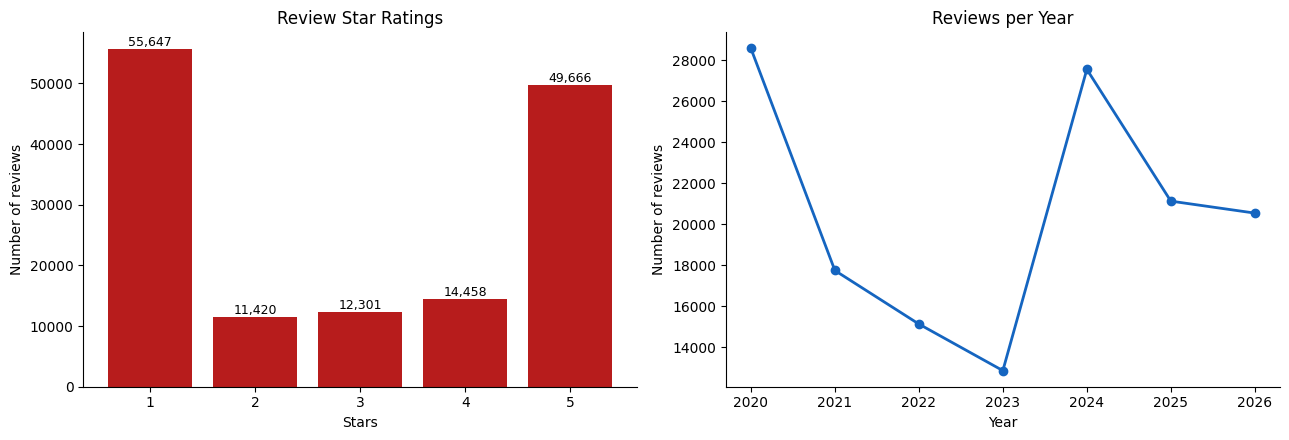

Total reviews: 143,492
Average rating: 2.94
Average review length: 24.3 words


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
rc = df_raw["rating"].value_counts().sort_index()
axes[0].bar(rc.index.astype(int).astype(str), rc.values, color="#B71C1C")
for x, y in zip(range(len(rc)), rc.values):
    axes[0].text(x, y, f"{y:,}", ha="center", va="bottom", fontsize=9)
axes[0].set_title("Review Star Ratings"); axes[0].set_xlabel("Stars")
axes[0].set_ylabel("Number of reviews"); axes[0].spines[["top","right"]].set_visible(False)
yr = df_raw.dropna(subset=["date"]).copy()
yr["year"] = yr["date"].dt.year
yc = yr["year"].value_counts().sort_index()
axes[1].plot(yc.index.astype(str), yc.values, marker="o", color="#1565C0", linewidth=2)
axes[1].set_title("Reviews per Year"); axes[1].set_xlabel("Year")
axes[1].set_ylabel("Number of reviews"); axes[1].spines[["top","right"]].set_visible(False)
plt.tight_layout()
plt.savefig("/kaggle/working/fig_dataset_overview.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Total reviews: {len(df_raw):,}")
print(f"Average rating: {df_raw['rating'].mean():.2f}")
print(f"Average review length: {df_raw['text'].astype(str).str.split().str.len().mean():.1f} words")


## 3. Cleaning the text


In [6]:
DetectorFactory.seed = SEED
LOW_INFO = {"good", "bad", "nice", "ok", "wow", "love it", "hate it",
            "very good", "very bad", "awesome", "terrible"}
SPAM_PATTERNS = [r"earn money", r"work from home", r"visit my channel",
                 r"check out my", r"promo code",
                 r"free followers", r"telegram", r"whatsapp"]
def detect_lang_safe(text):
    try:
        return detect(text)
    except LangDetectException:
        return "unknown"
def clean_text(text):
    text = str(text).strip().lower()
    text = emoji.replace_emoji(text, replace="")
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"<.*?>", " ", text)
    text = re.sub(r"[^a-zA-Z0-9\s\.\,\!\?\-\'\"]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text
def is_low_quality(text):
    if not isinstance(text, str):
        return True
    txt = text.strip()
    if len(txt) < 20 or len(txt.split()) < 4:
        return True
    if txt.lower() in LOW_INFO:
        return True
    if re.search(r"(.)\1{5,}", txt):
        return True
    return False
def is_spam_like(text):
    txt = text.lower()
    return any(re.search(p, txt) for p in SPAM_PATTERNS)
def remove_near_duplicates(frame, text_col="text_clean", threshold=97):
    """Remove near duplicates within blocks sharing the first 20 characters."""
    frame = frame.reset_index(drop=True)
    block = frame[text_col].str[:20]
    drop = set()
    for _, g in frame.groupby(block):
        if len(g) < 2:
            continue
        texts = g[text_col].tolist()
        sim = process.cdist(texts, texts, scorer=fuzz.ratio, workers=-1)
        gidx = g.index.to_numpy()
        for i in range(len(texts)):
            if gidx[i] in drop:
                continue
            dup = np.where(sim[i, i + 1:] >= threshold)[0] + i + 1
            drop.update(gidx[j] for j in dup)
    return frame.drop(index=list(drop)).reset_index(drop=True)


In [7]:
df = df_raw.copy()
df["text"] = df["text"].astype(str).str.strip()
df = df[df["text"].str.len() >= 15].copy()
df["lang"] = df["text"].apply(detect_lang_safe)
df = df[df["lang"] == "en"].copy()
df["text_clean"] = df["text"].apply(clean_text)
df = df[~df["text_clean"].apply(is_low_quality)]
df = df[~df["text_clean"].apply(is_spam_like)]
df = df.drop_duplicates(subset="text_clean").reset_index(drop=True)
df = remove_near_duplicates(df, threshold=97)
df["review_id"] = np.arange(len(df))

print("Cleaned English reviews:", len(df))


Cleaned English reviews: 116251


## 4. Opinion Segmentation


In [8]:
for name in (
    "extractor_model", "extractor_tok",
    "pilot_model", "pilot_tok"
):
    if name in globals():
        del globals()[name]

gc.collect()
torch.cuda.empty_cache()


nlp = spacy.load(
    "en_core_web_sm",
    disable=["tagger", "attribute_ruler", "lemmatizer", "ner"]
)

MIN_TOKENS = 4
MIN_PART_TOKENS = 4

CONTRAST = re.compile(r"\b(?:but|however)\b", re.I)

_LEAD_CONNECT = re.compile(
    r"^(?:and|or|so|also|then|plus|because|but|however|which|that)\b[\s,]*",
    re.I
)
_SUBJECTLESS = re.compile(
    r"^(?:are|is|was|were|am|be|been|being|has|have|had)\b",
    re.I
)
_DEPENDENT = re.compile(
    r"^(?:no matter|even if|even though|whether|as long as|in case)\b",
    re.I
)

def _tidy(seg):
    seg = _LEAD_CONNECT.sub("", str(seg).strip(" ,.-"))
    return seg.strip(" ,.-")

def _valid(seg, min_tok):
    toks = seg.split()

    if len(toks) < min_tok:
        return False
    if _SUBJECTLESS.match(seg):
        return False
    if _DEPENDENT.match(seg) and len(toks) < 12:
        return False

    return True

def split_doc_into_segments(doc):
    segments = []

    for sent in doc.sents:
        s = _tidy(sent.text)

        if not s:
            continue

        parts = [_tidy(p) for p in CONTRAST.split(s)]
        parts = [p for p in parts if p]

        if len(parts) >= 2 and all(
            _valid(p, MIN_PART_TOKENS) for p in parts
        ):
            segments.extend(parts)
        elif _valid(s, MIN_TOKENS):
            segments.append(s)

    return segments

def split_review_into_segments(text):
    return split_doc_into_segments(nlp(str(text)))


segment_rows = []

for row, doc in zip(
    df.itertuples(index=False),
    nlp.pipe(df["text_clean"].astype(str), batch_size=256)
):
    for seg_id, seg in enumerate(split_doc_into_segments(doc)):
        segment_rows.append({
            "review_id": row.review_id,
            "segment_id": seg_id,
            "text_clean": seg,
            "rating": row.rating,
            "date": row.date
        })

segments_df = pd.DataFrame(
    segment_rows,
    columns=["review_id", "segment_id", "text_clean", "rating", "date"]
)

assert not segments_df.empty, "No segments generated."

print("Total opinion segments:", len(segments_df))
print("Source reviews:", segments_df["review_id"].nunique())

display(segments_df.head(15))


Total opinion segments: 252130
Source reviews: 115300


,review_id,segment_id,text_clean,rating,date
0,0,0,'s an awesome movie,4,2026-11-13 07:22:57
1,1,0,"tyler perry deserves a statue of himself, caus...",5,2026-11-13 06:52:59
2,2,0,it was sooo unavailable,1,2026-11-13 06:19:41
3,3,0,netflix very loyal to subscribers,5,2026-11-13 06:14:27
4,4,0,it's the best movie ever,5,2026-11-13 05:53:37
5,5,0,offline downloads expire like 2 days after i d...,1,2026-11-13 05:47:10
6,5,1,netflix is just making up their own rules as t...,1,2026-11-13 05:47:10
7,5,2,anything stated in the app is no longer to be ...,1,2026-11-13 05:47:10
8,5,3,this is the reason people cancel you can't eve...,1,2026-11-13 05:47:10
9,6,0,i'd rate netflix 9.5 10 from your side!,5,2026-11-13 05:45:51


## 5. Silver Annotations


In [9]:
LLM_ID = "Qwen/Qwen2.5-7B-Instruct"
N_LLM = 6000
LLM_BATCH = 8
SWOT_DEFINITION = """Classify an app review segment into SWOT categories.

- Strength: Praise for an existing feature, content, quality, value, or user experience.
- Weakness: An existing problem, bug, crash, error, poor support, or dissatisfaction with the service.
- Opportunity: A request for a new feature, additional content, language support, or an improvement that is not currently available.
- Threat: A business risk related to pricing, cancellation, switching to competitors, or loss of trust.

Rules:
- Existing bugs, crashes and requests to fix existing problems are Weakness.
- Requests for new features, content or languages are Opportunity.
- Pricing complaints, cancellation intentions, competitor comparisons and loss of trust are Threat.
- Praise for existing aspects of the service is Strength.
- A segment may receive multiple labels if it expresses distinct opinions belonging to different categories.
- Classify based on the meaning of the text.
"""

FEW_SHOT = """Segment: "great quality and streaming is fast" -> Strength
Segment: "app keeps crashing" -> Weakness
Segment: "should add tamil subtitles" -> Opportunity
Segment: "cancelling, too expensive" -> Threat
Segment: "content is poor and boring" -> Weakness
Segment: "amazon prime is cheaper" -> Threat
Segment: "clean interface but crashes a lot" -> Strength, Weakness"""

if NEED_LLM:
    if not torch.cuda.is_available():
        raise RuntimeError("Qwen annotation requires a CUDA GPU; attach the cached silver CSV instead.")

    llm_tokenizer = AutoTokenizer.from_pretrained(LLM_ID)
    llm_tokenizer.padding_side = "left"
    llm_tokenizer.truncation_side = "left"
    if llm_tokenizer.pad_token is None:
        llm_tokenizer.pad_token = llm_tokenizer.eos_token

    bnb_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_compute_dtype=torch.float16,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_use_double_quant=True
    )
    llm_model = AutoModelForCausalLM.from_pretrained(
        LLM_ID, quantization_config=bnb_config, device_map="auto"
    )
    llm_model.eval()


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

... (3 outputs left out)

model-00003-of-00004.safetensors:   0%|          | 0.00/3.86G [00:00<?, ?B/s]

model-00004-of-00004.safetensors:   0%|          | 0.00/3.56G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

In [10]:
def build_prompt(text, rating=None):
    user_prompt = (
        SWOT_DEFINITION + "\n\n" + FEW_SHOT +
        "\n\nReturn ONLY the category names, nothing else.\n\n"
        f'Segment: "{text}" ->'
    )

    messages = [
        {
            "role": "system",
            "content": "You classify app review segments into SWOT categories."
        },
        {
            "role": "user",
            "content": user_prompt
        },
    ]

    return llm_tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )


In [11]:
def parse_labels(response):
    names = "|".join(SWOT_LABELS)
    pattern = rf"\s*({names})(?:\s*[,|/]\s*({names}))*\s*"
    response = str(response).strip().rstrip(".")
    if not re.fullmatch(pattern, response, flags=re.I):
        return []
    matches = re.findall(rf"\b({names})\b", str(response), flags=re.I)
    lookup = {label.casefold(): label for label in SWOT_LABELS}
    return list(dict.fromkeys(lookup[m.casefold()] for m in matches))


def llm_classify_batch(texts, ratings=None):
    prompts = [build_prompt(str(t)) for t in texts]
    inputs = llm_tokenizer(
        prompts, return_tensors="pt", padding=True,
        truncation=True, max_length=1024
    ).to(llm_model.device)
    with torch.inference_mode():
        generated = llm_model.generate(
            **inputs, max_new_tokens=20, do_sample=False,
            pad_token_id=llm_tokenizer.pad_token_id
        )
    output = llm_tokenizer.batch_decode(
        generated[:, inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    )
    return [parse_labels(s) for s in output]


## 6. Human Annotations


In [12]:
HUMAN_PATH = "/kaggle/input/datasets/anastasiapolitidou/gold-segments/gold_segments.csv"
TEST_FILES = list(Path("/kaggle/input").rglob("netflix_human_test.csv"))
if not os.path.isfile(HUMAN_PATH):
    raise FileNotFoundError("Missing gold-segments/gold_segments.csv in Kaggle Inputs.")
if len(TEST_FILES) != 1:
    raise FileNotFoundError("Attach exactly one netflix_human_test.csv to Kaggle Inputs.")

input_checksums = {
    "human_development_csv": hashlib.sha256(Path(HUMAN_PATH).read_bytes()).hexdigest(),
    "human_test_csv": hashlib.sha256(TEST_FILES[0].read_bytes()).hexdigest()
}
human_gold = pd.read_csv(HUMAN_PATH).rename(columns={"segment_text": "text_clean"})
human_test = pd.read_csv(TEST_FILES[0]).rename(columns={"segment_text": "text_clean"})

for frame in (human_gold, human_test):
    required = {"text_clean", "original_review", "manual_swot"}
    if not required.issubset(frame.columns):
        raise ValueError(f"Human CSV missing columns: {required - set(frame.columns)}")
    if frame[list(required)].isna().any().any():
        raise ValueError("Human CSV contains missing text/review/SWOT values.")
    frame["text_clean"] = frame["text_clean"].astype(str).str.strip()
    frame["manual_swot"] = frame["manual_swot"].astype(str).str.strip()
    frame["parent_key"] = frame["original_review"].map(clean_text)
    assert frame["manual_swot"].isin(SWOT_LABELS).all()
    assert frame["parent_key"].ne("").all()
    assert frame["text_clean"].str.strip().ne("").all()
    frame["segment_key"] = frame["text_clean"].map(clean_text)
    duplicates = frame.groupby(["parent_key", "segment_key"])["manual_swot"].nunique()
    if duplicates.gt(1).any():
        raise ValueError("The same human-labeled opinion has conflicting labels.")
    before = len(frame)
    frame.drop_duplicates(["parent_key", "segment_key"], inplace=True)
    frame.reset_index(drop=True, inplace=True)
    if len(frame) != before:
        print("Duplicate human rows removed:", before - len(frame))

source_date_by_parent = (
    df_raw_all.assign(parent_key=df_raw_all["text"].map(clean_text))
    .groupby("parent_key", sort=False)["date"].min()
)
source_date_audit = {}
for name, frame in [("Human development", human_gold), ("Human test", human_test)]:
    frame["verified_source_date"] = frame["parent_key"].map(source_date_by_parent)
    pre2020 = (frame["verified_source_date"].notna()
               & frame["verified_source_date"].lt(SOURCE_START_DATE))
    unknown_date = frame["verified_source_date"].isna()
    exclusion = pre2020 | unknown_date
    source_date_audit[name] = {
        "original_segments": int(len(frame)),
        "pre2020_excluded": int(pre2020.sum()),
        "unverified_date_excluded": int(unknown_date.sum()),
        "eligible_segments": int((~exclusion).sum())
    }
    print(name, source_date_audit[name])
    frame.drop(index=frame.index[exclusion], inplace=True)
    frame.reset_index(drop=True, inplace=True)
    assert frame["verified_source_date"].ge(SOURCE_START_DATE).all()

if human_gold.empty or human_test.empty:
    raise ValueError("Human labels or test empty after strict date eligibility. Check source text matching.")
for name, frame in [("Human development", human_gold), ("Human test", human_test)]:
    if not set(SWOT_LABELS).issubset(set(frame["manual_swot"])):
        raise ValueError(f"{name} is missing one or more SWOT labels after date filtering.")

assert set(human_gold["parent_key"]).isdisjoint(human_test["parent_key"]), (
    "Human development/test share original review text"
)
print("Human development labels:", len(human_gold))
print("Human test:", len(human_test))


Human development {'original_segments': 300, 'pre2020_excluded': 43, 'unverified_date_excluded': 23, 'eligible_segments': 234}
Human test {'original_segments': 200, 'pre2020_excluded': 0, 'unverified_date_excluded': 0, 'eligible_segments': 200}
Human development labels: 234
Human test: 200


In [13]:
parent_by_id = df.set_index("review_id")["text_clean"]
llm_pool = segments_df.copy()
llm_pool["source_review_text"] = llm_pool["review_id"].map(parent_by_id)

NEAR_DUPLICATE_THRESHOLD = 97

def find_near_matches(values, reference):
    choices = list(dict.fromkeys(str(v) for v in reference))
    if not choices:
        return set()
    return {
        value for value in set(str(v) for v in values)
        if process.extractOne(
            value, choices, scorer=fuzz.ratio, score_cutoff=NEAR_DUPLICATE_THRESHOLD
        ) is not None
    }

human_sources = set(human_gold["parent_key"]) | set(human_test["parent_key"])
near_test_sources = find_near_matches(human_gold["parent_key"], human_test["parent_key"])
near_test_segments = find_near_matches(human_gold["segment_key"], human_test["segment_key"])
blocked = human_gold["parent_key"].isin(near_test_sources) | human_gold["segment_key"].isin(near_test_segments)
blocked_parents = set(human_gold.loc[blocked, "parent_key"])
before = len(human_gold)
human_gold = human_gold.loc[~human_gold["parent_key"].isin(blocked_parents)].reset_index(drop=True)
print("Development rows excluded for near duplication with test:", before - len(human_gold))
human_segments = set(pd.concat([
    human_gold["text_clean"], human_test["text_clean"]
]).map(clean_text))

llm_pool = llm_pool.loc[
    ~llm_pool["source_review_text"].isin(human_sources)
    & ~llm_pool["text_clean"].map(clean_text).isin(human_segments)
].drop_duplicates(subset="text_clean").copy()

if NEED_LLM:
    sample = llm_pool.sample(min(N_LLM, len(llm_pool)), random_state=SEED)
    rows = []
    for i in tqdm(range(0, len(sample), LLM_BATCH), desc="Qwen labels"):
        batch = sample.iloc[i:i + LLM_BATCH]
        labels = llm_classify_batch(batch["text_clean"].tolist())
        for row, lab in zip(batch.itertuples(index=False), labels):
            if lab:
                rows.append({
                    "source_review_text": row.source_review_text,
                    "text_clean": row.text_clean,
                    "rating": row.rating,
                    "labels": lab
                })
    llm_df = pd.DataFrame(rows)
    if llm_df.empty:
        raise ValueError("Qwen did not return any valid labels.")
    save_df = llm_df.copy()
    save_df["labels"] = save_df["labels"].str.join("|")
    save_df.to_csv("/kaggle/working/silver_labeled_with_source.csv", index=False)
else:
    llm_df = pd.read_csv(LLM_CACHE)
    required = {"text_clean", "source_review_text", "labels"}
    if not required.issubset(llm_df.columns):
        raise ValueError("Silver CSV must contain text_clean, source_review_text and labels.")
    llm_df["labels"] = llm_df["labels"].fillna("").apply(
        lambda s: [v.strip() for v in str(s).split("|") if v.strip()]
    )

llm_df["source_review_text"] = llm_df["source_review_text"].map(clean_text)
llm_df["text_clean"] = llm_df["text_clean"].astype(str).map(clean_text)
llm_df = llm_df.loc[llm_df["labels"].apply(
    lambda labels: bool(labels) and set(labels).issubset(set(SWOT_LABELS))
)].copy()



all_segments = segments_df.assign(
    source_review_text=segments_df["review_id"].map(parent_by_id)
)
known_pairs = set(zip(
    all_segments["source_review_text"].map(clean_text),
    all_segments["text_clean"].map(clean_text)
))
before_cache_filter = len(llm_df)
pairs = list(zip(llm_df["source_review_text"], llm_df["text_clean"]))
llm_df = llm_df.loc[[pair in known_pairs for pair in pairs]].copy()
print("Silver pairs excluded (outside current 2020+ corpus):", before_cache_filter - len(llm_df))

before_human_exclusion = len(llm_df)
llm_df = llm_df.loc[
    ~llm_df["source_review_text"].isin(human_sources)
    & ~llm_df["text_clean"].isin(human_segments)
].copy()
print("Silver pairs excluded (human source/segment overlap):", before_human_exclusion - len(llm_df))
near_sources = find_near_matches(llm_df["source_review_text"], human_sources)
near_segments = find_near_matches(llm_df["text_clean"], human_segments)
before = len(llm_df)
llm_df = llm_df.loc[
    ~llm_df["source_review_text"].isin(near_sources)
    & ~llm_df["text_clean"].isin(near_segments)
].copy()
print("Silver rows excluded for near duplication with human data:", before - len(llm_df))



llm_df["label_string"] = llm_df["labels"].map(lambda x: "|".join(sorted(x)))
conflict_counts = llm_df.groupby("text_clean")["label_string"].transform("nunique")
conflicts = int((conflict_counts > 1).sum())
llm_df = llm_df.loc[conflict_counts.eq(1)].drop_duplicates(
    subset=["text_clean"]
).drop(columns=["label_string"]).reset_index(drop=True)
print("Conflicting duplicate silver annotations removed:", conflicts)

if llm_df.empty:
    raise ValueError("No matching silver annotations remain. Check Kaggle Inputs.")
assert set(llm_df["source_review_text"]).isdisjoint(human_sources)
assert set(llm_df["text_clean"]).isdisjoint(human_segments)
print("Validated silver segments:", len(llm_df))

if NEED_LLM:
    del llm_model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


input_checksums["silver_training_rows"] = hashlib.sha256(
    llm_df[["source_review_text", "text_clean", "labels"]]
    .to_json(orient="split", index=False).encode()
).hexdigest()


Development rows excluded for near duplication with test: 0


Qwen labels:   0%|          | 0/750 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Silver pairs excluded (outside current 2020+ corpus): 0
Silver pairs excluded (human source/segment overlap): 0
Silver rows excluded for near duplication with human data: 0
Conflicting duplicate silver annotations removed: 0
Validated silver segments: 5932


## 7. Human Development Data and Leakage Checks


In [14]:
HUMAN_WEIGHT = 3
CV_FOLDS = 3
MAX_CV_EPOCHS = 3
EARLY_STOPPING_PATIENCE = 1
EARLY_STOPPING_THRESHOLD = 0.0
CV_LEARNING_RATE = 1e-5
FROZEN_LAYERS = 6
CLASSIFIER_DROPOUT = 0.20
WEIGHT_DECAY = 0.10
LABEL_SMOOTHING = 0.10
WARMUP_RATIO = 0.10

human_development = human_gold.copy().reset_index(drop=True)
human_development["_review_key"] = human_development["parent_key"]
review_keys = sorted(human_development["_review_key"].unique())
parents = list(range(len(review_keys)))

def find_root(i):
    while parents[i] != i:
        parents[i] = parents[parents[i]]
        i = parents[i]
    return i

for i, key in enumerate(review_keys):
    matches = process.extract(
        key, review_keys[i + 1:], scorer=fuzz.ratio,
        score_cutoff=NEAR_DUPLICATE_THRESHOLD, limit=None
    )
    for _, _, position in matches:
        left, right = find_root(i), find_root(i + 1 + position)
        parents[right] = left
group_by_review = {key: find_root(i) for i, key in enumerate(review_keys)}
human_development["_cv_group"] = human_development["_review_key"].map(group_by_review)
if human_development["_cv_group"].nunique() < CV_FOLDS:
    raise ValueError("Too few independent human review groups for cross-validation.")
test = human_test.copy()
test["_review_key"] = test["parent_key"]

n_multi = int((llm_df["labels"].str.len() != 1).sum())
llm_single = llm_df.loc[llm_df["labels"].str.len().eq(1)].copy()
llm_single["primary_label"] = llm_single["labels"].str[0]
llm_single["_review_key"] = llm_single["source_review_text"].map(clean_text)
llm_train = llm_single.loc[
    ~llm_single["_review_key"].isin(
        set(human_development["_review_key"]) | set(test["_review_key"])
    )
].reset_index(drop=True).copy()
if llm_train.empty:
    raise ValueError("No eligible silver examples remain for training.")
assert set(llm_train["_review_key"]).isdisjoint(set(human_development["_review_key"]))
assert set(llm_train["_review_key"]).isdisjoint(set(test["_review_key"]))
assert set(human_development["_review_key"]).isdisjoint(set(test["_review_key"]))

def mixed_training_frame(human_rows, seed):
    silver = llm_train[["text_clean", "primary_label"]].copy()
    gold_rows = human_rows.assign(primary_label=human_rows["manual_swot"])[
        ["text_clean", "primary_label"]
    ].copy()
    mixed = pd.concat([silver] + [gold_rows] * HUMAN_WEIGHT, ignore_index=True)
    return mixed.sample(frac=1, random_state=seed).reset_index(drop=True)

train_df = mixed_training_frame(human_development, SEED)
print("Human development segments:", len(human_development))
print("Human source reviews:", human_development["_review_key"].nunique())
print("Single-label Qwen segments:", len(llm_train))
print("Multi-label Qwen segments excluded:", n_multi)
print("Human repetition:", HUMAN_WEIGHT)
print("Final training rows:", len(train_df))
print("Cross-validation folds:", CV_FOLDS)


Human development segments: 234
Human source reviews: 93
Single-label Qwen segments: 5324
Multi-label Qwen segments excluded: 608
Human repetition: 3
Final training rows: 6026
Cross-validation folds: 3


## 8. Tokenization


In [15]:
CLASSIFIER_ID = "FacebookAI/roberta-base"
MAX_LENGTH = 256
label2id = {label: i for i, label in enumerate(SWOT_LABELS)}
id2label = {i: label for label, i in label2id.items()}
classifier_tokenizer = AutoTokenizer.from_pretrained(CLASSIFIER_ID)

def make_dataset(frame, label_column):
    dataset = Dataset.from_dict({
        "text": frame["text_clean"].astype(str).tolist(),
        "labels": [label2id[l] for l in frame[label_column]]
    })
    return dataset.map(
        lambda batch: classifier_tokenizer(
            batch["text"], truncation=True, max_length=MAX_LENGTH
        ), batched=True, remove_columns=["text"]
    )


final_train_ds = make_dataset(train_df, "primary_label")
data_collator = DataCollatorWithPadding(tokenizer=classifier_tokenizer)
print("Final refit training samples:", len(final_train_ds))


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/6026 [00:00<?, ? examples/s]

Final refit training samples: 6026


In [16]:
def segment_keys(frame):
    return set(frame["text_clean"].fillna("").astype(str).map(clean_text)) - {""}

segment_splits = {
    "Development train + silver": segment_keys(train_df),
    "Test": segment_keys(human_test),
}
for a, b in combinations(segment_splits, 2):
    assert not (segment_splits[a] & segment_splits[b]), f"Overlapping segments: {a}, {b}"
assert set(llm_train["_review_key"]).isdisjoint(set(test["_review_key"]))
assert set(human_development["_review_key"]).isdisjoint(set(test["_review_key"]))
print("Overlapping review groups with test: 0")
print("Overlapping cleaned segments with test: 0")


Overlapping review groups with test: 0
Overlapping cleaned segments with test: 0


## 9. RoBERTa Training with Cross-Validation and Early Stopping


In [17]:
for name in ["trainer", "classifier_model", "final_model"]:
    globals().pop(name, None)
gc.collect()
torch.cuda.empty_cache()

OUTPUT_DIR = Path("/kaggle/working/swot_roberta_base_regularized")
if OUTPUT_DIR.exists():
    archived = OUTPUT_DIR.with_name(
        OUTPUT_DIR.name + "_" + datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f")
    )
    OUTPUT_DIR.rename(archived)
OUTPUT_DIR.mkdir(parents=True)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predicted = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, predicted),
        "macro_f1": f1_score(
            labels, predicted, labels=list(range(len(SWOT_LABELS))),
            average="macro", zero_division=0
        )
    }

def new_roberta():
    model = AutoModelForSequenceClassification.from_pretrained(
        CLASSIFIER_ID, num_labels=len(SWOT_LABELS),
        problem_type="single_label_classification",
        id2label=id2label, label2id=label2id,
        classifier_dropout=CLASSIFIER_DROPOUT
    )
    assert len(model.roberta.encoder.layer) == 12
    for parameter in model.roberta.embeddings.parameters():
        parameter.requires_grad = False
    for layer in model.roberta.encoder.layer[:FROZEN_LAYERS]:
        for parameter in layer.parameters():
            parameter.requires_grad = False
    return model

def training_args(folder, evaluate):
    return TrainingArguments(
        output_dir=str(folder), num_train_epochs=MAX_CV_EPOCHS,
        per_device_train_batch_size=2, gradient_accumulation_steps=8,
        per_device_eval_batch_size=4, learning_rate=CV_LEARNING_RATE,
        weight_decay=WEIGHT_DECAY, label_smoothing_factor=LABEL_SMOOTHING,
        warmup_ratio=WARMUP_RATIO, lr_scheduler_type="linear", max_grad_norm=1.0,
        eval_strategy="epoch" if evaluate else "no",
        save_strategy="epoch" if evaluate else "no",
        load_best_model_at_end=bool(evaluate),
        metric_for_best_model="validation_loss" if evaluate else None,
        greater_is_better=False if evaluate else None,
        save_only_model=True, save_total_limit=1,
        logging_strategy="epoch", logging_nan_inf_filter=False,
        fp16=torch.cuda.is_available(), gradient_checkpointing=True,
        gradient_checkpointing_kwargs={"use_reentrant": False},
        report_to="none", seed=SEED, data_seed=SEED, dataloader_num_workers=0
    )

class ValidationEarlyStopping(EarlyStoppingCallback):
    def on_evaluate(self, args, state, control, metrics, **kwargs):
        if "eval_validation_loss" in metrics:
            return super().on_evaluate(args, state, control, metrics, **kwargs)
        return control

class StopAtSelectedEpoch(TrainerCallback):
    def __init__(self, epoch):
        self.epoch = int(epoch)

    def on_epoch_end(self, args, state, control, **kwargs):
        if state.epoch is not None and state.epoch + 1e-8 >= self.epoch:
            control.should_training_stop = True
        return control

folds = None
for cv_fold_seed in range(SEED, SEED + 100):
    splitter = StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=cv_fold_seed)
    candidate_folds = list(splitter.split(
        human_development, human_development["manual_swot"],
        groups=human_development["_cv_group"]
    ))
    if all(human_development.iloc[v]["manual_swot"].nunique() == len(SWOT_LABELS)
           for _, v in candidate_folds):
        folds = candidate_folds
        break
if folds is None:
    raise ValueError("Cannot form three review-grouped folds containing every SWOT class.")

cv_rows, fold_details, oof_rows = [], [], []
for fold_number, (train_idx, val_idx) in enumerate(folds, start=1):
    print(f"Fold {fold_number}/{CV_FOLDS}")
    fold_train = human_development.iloc[train_idx].copy()
    fold_val = human_development.iloc[val_idx].copy()
    near_segments = find_near_matches(
        fold_train["text_clean"].map(clean_text), fold_val["text_clean"].map(clean_text)
    )
    fold_train = fold_train.loc[
        ~fold_train["text_clean"].map(clean_text).isin(near_segments)
    ].copy()
    assert not fold_train.empty
    assert set(fold_train["_cv_group"]).isdisjoint(fold_val["_cv_group"])
    assert set(fold_val["_review_key"]).isdisjoint(llm_train["_review_key"])
    assert set(fold_val["_review_key"]).isdisjoint(test["_review_key"])
    mixed = mixed_training_frame(fold_train, SEED)
    train_dataset = make_dataset(mixed, "primary_label")
    human_train_dataset = make_dataset(fold_train, "manual_swot")
    val_dataset = make_dataset(fold_val, "manual_swot")
    fold_folder = OUTPUT_DIR / "cv_runs" / f"fold_{fold_number}"
    set_seed(SEED)
    model = new_roberta()
    trainer = Trainer(
        model=model, args=training_args(fold_folder, True), train_dataset=train_dataset,
        eval_dataset={"train": human_train_dataset, "validation": val_dataset},
        processing_class=classifier_tokenizer, data_collator=data_collator,
        compute_metrics=compute_metrics,
        callbacks=[ValidationEarlyStopping(
            early_stopping_patience=EARLY_STOPPING_PATIENCE,
            early_stopping_threshold=EARLY_STOPPING_THRESHOLD
        )]
    )
    trainer.train()
    history = trainer.state.log_history
    train_logs = {entry["step"]: entry for entry in history if "eval_train_loss" in entry}
    val_logs = [entry for entry in history if "eval_validation_loss" in entry]
    observed_epochs = []
    for entry in val_logs:
        epoch = int(round(entry["epoch"]))
        if abs(entry["epoch"] - epoch) > 1e-6:
            raise RuntimeError("Validation must be evaluated at completed epochs.")
        observed_epochs.append(epoch)
        train_entry = train_logs[entry["step"]]
        values = [train_entry["eval_train_loss"], entry["eval_validation_loss"],
                  entry["eval_validation_accuracy"], entry["eval_validation_macro_f1"]]
        if not np.isfinite(values).all():
            raise FloatingPointError("Non-finite fold evaluation measurements.")
        cv_rows.append({
            "fold": fold_number, "epoch": epoch,
            "train_loss": float(values[0]), "val_loss": float(values[1]),
            "val_accuracy": float(values[2]), "val_macro_f1": float(values[3])
        })
    if observed_epochs != list(range(1, len(val_logs) + 1)):
        raise RuntimeError("The fold history has missing or repeated epochs.")
    best = min(val_logs, key=lambda entry: (entry["eval_validation_loss"], entry["epoch"]))
    best_epoch = int(round(best["epoch"]))
    assert np.isclose(trainer.state.best_metric, best["eval_validation_loss"])
    assert Path(trainer.state.best_model_checkpoint).name == f"checkpoint-{best['step']}"
    predicted = np.argmax(trainer.predict(val_dataset).predictions, axis=-1)
    assert np.isclose(
        f1_score([label2id[x] for x in fold_val["manual_swot"]], predicted,
                 labels=list(range(len(SWOT_LABELS))), average="macro", zero_division=0),
        best["eval_validation_macro_f1"]
    )
    for index, label in zip(val_idx, predicted):
        oof_rows.append({"development_index": int(index), "fold": fold_number,
                         "true": human_development.iloc[index]["manual_swot"],
                         "predicted": id2label[int(label)]})
    fold_details.append({
        "fold": fold_number, "best_epoch": best_epoch,
        "last_epoch": observed_epochs[-1],
        "stopped_early": observed_epochs[-1] < MAX_CV_EPOCHS,
        "validation_loss": float(best["eval_validation_loss"]),
        "validation_accuracy": float(best["eval_validation_accuracy"]),
        "validation_macro_f1": float(best["eval_validation_macro_f1"]),
        "human_train_segments": len(fold_train), "validation_segments": len(fold_val),
        "mixed_training_rows": len(mixed),
        "near_duplicate_train_segments_removed": len(train_idx) - len(fold_train),
        **{label: int((fold_val["manual_swot"] == label).sum()) for label in SWOT_LABELS}
    })
    (OUTPUT_DIR / f"fold_{fold_number}_history.json").write_text(
        json.dumps(history, indent=2), encoding="utf-8"
    )
    del trainer, model, train_dataset, human_train_dataset, val_dataset
    shutil.rmtree(fold_folder)
    gc.collect()
    torch.cuda.empty_cache()

cv_results = pd.DataFrame(cv_rows)
cv_fold_summary = pd.DataFrame(fold_details)
assert not cv_results.duplicated(["fold", "epoch"]).any()
assert cv_fold_summary["fold"].nunique() == CV_FOLDS == 3
selected_epochs = int(np.median(cv_fold_summary["best_epoch"]))
selected_lr = float(CV_LEARNING_RATE)
cv_selected_loss = float(cv_fold_summary["validation_loss"].mean())
cv_best_macro_f1 = float(cv_fold_summary["validation_macro_f1"].mean())
cv_best_macro_std = float(cv_fold_summary["validation_macro_f1"].std())
cv_results.to_csv(OUTPUT_DIR / "cv_fold_results.csv", index=False)
cv_fold_summary.to_csv(OUTPUT_DIR / "cv_fold_info.csv", index=False)
pd.DataFrame(oof_rows).sort_values("development_index").to_csv(
    OUTPUT_DIR / "cv_oof_predictions.csv", index=False
)
print(f"Final training duration: {selected_epochs} complete epoch(s), median of fold-best epochs")
print(f"CV Macro F1 at fold-best checkpoints: {cv_best_macro_f1:.4f} (+/- {cv_best_macro_std:.4f} SD)")

set_seed(SEED)
classifier_model = new_roberta()
final_args = training_args(OUTPUT_DIR / "final_refit", False)
trainer = Trainer(
    model=classifier_model, args=final_args, train_dataset=final_train_ds,
    processing_class=classifier_tokenizer, data_collator=data_collator,
    callbacks=[StopAtSelectedEpoch(selected_epochs)]
)
trainer.train()
assert abs(trainer.state.epoch - selected_epochs) < 1e-6
selected_final_steps = int(trainer.state.global_step)
planned_final_steps = int(trainer.state.max_steps)
FINAL_MODEL_DIR = OUTPUT_DIR / "best_model"
trainer.save_model(str(FINAL_MODEL_DIR))
classifier_tokenizer.save_pretrained(str(FINAL_MODEL_DIR))
(OUTPUT_DIR / "training_history.json").write_text(
    json.dumps(trainer.state.log_history, indent=2), encoding="utf-8"
)
selection_rule = "median_of_fold_best_validation_loss_epochs"
training_config = {
    "model_type": CLASSIFIER_ID, "learning_rate": CV_LEARNING_RATE,
    "max_cv_epochs": MAX_CV_EPOCHS, "selected_epoch": selected_epochs,
    "cv_folds": CV_FOLDS, "seed": SEED, "fold_assignment_seed": cv_fold_seed,
    "fold_assignment_rule": "first_seed_with_all_classes_without_using_model_scores",
    "pretrained_revision": getattr(classifier_model.config, "_commit_hash", None),
    "freeze_embeddings": True, "frozen_first_transformer_layers": FROZEN_LAYERS,
    "classifier_dropout": CLASSIFIER_DROPOUT, "weight_decay": WEIGHT_DECAY,
    "label_smoothing": LABEL_SMOOTHING, "warmup_ratio": WARMUP_RATIO,
    "human_weight": HUMAN_WEIGHT, "max_length": MAX_LENGTH,
    "per_device_train_batch_size": 2, "gradient_accumulation_steps": 8,
    "scheduler_horizon_epochs": MAX_CV_EPOCHS,
    "early_stopping_metric": "validation_loss",
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "early_stopping_threshold": EARLY_STOPPING_THRESHOLD,
    "restore_best_checkpoint_in_each_fold": True,
    "selection_rule": selection_rule,
    "cv_metrics_scope": "fold_specific_best_checkpoints_used_for_model_selection",
    "cv_macro_f1_mean": cv_best_macro_f1, "cv_macro_f1_sd": cv_best_macro_std,
    "cv_mean_best_fold_validation_loss": cv_selected_loss,
    "selected_final_optimizer_steps": selected_final_steps,
    "planned_final_optimizer_steps": planned_final_steps,
    "near_duplicate_threshold": NEAR_DUPLICATE_THRESHOLD,
    "source_sha256": source_sha256, "input_checksums": input_checksums,
    "test_used_for_classifier_training": False,
    "test_used_for_checkpoint_selection": False
}
for filename in ["training_config.json", "cv_selection.json"]:
    (OUTPUT_DIR / filename).write_text(json.dumps(training_config, indent=2), encoding="utf-8")
print("Final model:", FINAL_MODEL_DIR)


Fold 1/3


Map:   0%|          | 0/5774 [00:00<?, ? examples/s]

Map:   0%|          | 0/150 [00:00<?, ? examples/s]

Map:   0%|          | 0/84 [00:00<?, ? examples/s]

model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at FacebookAI/roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


... (13 outputs left out)

Final training duration: 2 complete epoch(s), median of fold-best epochs
CV Macro F1 at fold-best checkpoints: 0.7613 (+/- 0.0287 SD)


Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at FacebookAI/roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Step,Training Loss
189,1.051700
378,0.693200


Final model: /kaggle/working/swot_roberta_base_regularized/best_model


In [18]:
display(cv_fold_summary[[
    "fold", "best_epoch", "last_epoch", "stopped_early", "validation_loss",
    "validation_accuracy", "validation_macro_f1"
]].round(4))


,fold,best_epoch,last_epoch,stopped_early,validation_loss,validation_accuracy,validation_macro_f1
0,1,2,3,False,0.6582,0.8571,0.7864
1,2,3,3,False,0.7526,0.7875,0.7301
2,3,2,3,False,0.7116,0.7857,0.7675


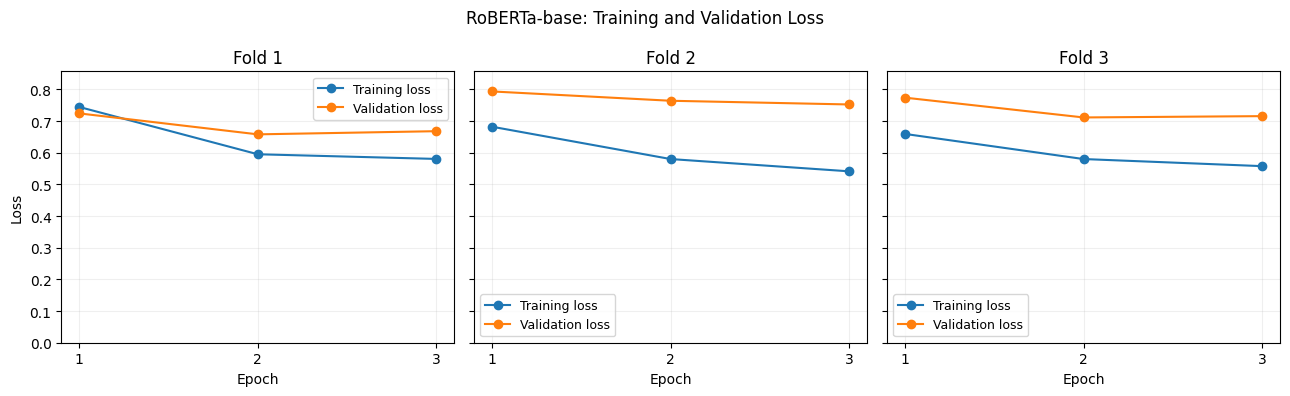

In [19]:
fig, axes = plt.subplots(1, CV_FOLDS, figsize=(13, 4), sharey=True)
upper = 1.08 * max(cv_results["train_loss"].max(), cv_results["val_loss"].max())
for fold_number, ax in enumerate(axes, start=1):
    rows = cv_results.loc[cv_results["fold"].eq(fold_number)].sort_values("epoch")
    ax.plot(rows["epoch"], rows["train_loss"], "o-", color="tab:blue", label="Training loss")
    ax.plot(rows["epoch"], rows["val_loss"], "o-", color="tab:orange", label="Validation loss")
    ax.set_title(f"Fold {fold_number}")
    ax.set_xlabel("Epoch")
    ax.set_xticks(range(1, MAX_CV_EPOCHS + 1))
    ax.set_ylim(0, upper)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=9)
axes[0].set_ylabel("Loss")
fig.suptitle("RoBERTa-base: Training and Validation Loss")
fig.tight_layout()
for destination in [Path("/kaggle/working/fig_cv_train_validation_loss.png"), OUTPUT_DIR / "fig_cv_train_validation_loss.png"]:
    fig.savefig(destination, dpi=200, bbox_inches="tight")
plt.show()


## 10. Verify and Save Final Classifier


In [20]:
BASE_CHECKPOINT = OUTPUT_DIR / "best_model"
assert BASE_CHECKPOINT.is_dir()
verified_dir = OUTPUT_DIR / "best_model_verified"
verified_dir.mkdir(parents=True, exist_ok=True)
selected_model, loading_info = AutoModelForSequenceClassification.from_pretrained(
    str(BASE_CHECKPOINT), local_files_only=True, output_loading_info=True
)
assert not loading_info["missing_keys"] and not loading_info["unexpected_keys"]
selected_model.save_pretrained(str(verified_dir), safe_serialization=True)
classifier_tokenizer.save_pretrained(str(verified_dir))
del selected_model

del trainer, classifier_model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
def validation_scores(folder, frame):
    model = AutoModelForSequenceClassification.from_pretrained(str(folder), local_files_only=True)
    model = model.to(device).eval()
    logits_all = []
    texts = frame["text_clean"].astype(str).tolist()
    with torch.inference_mode():
        for start in range(0, len(texts), 16):
            encoded = classifier_tokenizer(
                texts[start:start + 16], padding=True, truncation=True,
                max_length=MAX_LENGTH, return_tensors="pt"
            ).to(device)
            logits_all.append(model(**encoded).logits.float().cpu())
    logits = torch.cat(logits_all)
    truth = torch.tensor([label2id[x] for x in frame["manual_swot"]])
    loss = torch.nn.functional.cross_entropy(logits, truth).item()
    pred = logits.argmax(dim=1).numpy()
    scores = {
        "loss": float(loss),
        "macro_f1": float(f1_score(truth.numpy(), pred, labels=list(range(4)),
                                   average="macro", zero_division=0)),
        "accuracy": float(accuracy_score(truth.numpy(), pred))
    }
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return scores

selected_stage = f"RoBERTa-base with {FROZEN_LAYERS} frozen layers and grouped-CV early stopping"
selected_train_scores = validation_scores(verified_dir, human_development)
print("Human development (IN-SAMPLE, descriptive):",
      {k: round(v, 4) for k, v in selected_train_scores.items()})
print(f"3-fold CV Macro F1 at fold-best checkpoints: {cv_best_macro_f1:.4f} "
      f"(+/- {cv_best_macro_std:.4f} SD)")
print(f"Selected LR: {selected_lr:g}; epochs: {selected_epochs}; steps: {selected_final_steps}")

inference_params = {
    "model_type": CLASSIFIER_ID,
    "prediction_rule": "softmax_argmax",
    "problem_type": "single_label_classification",
    "swot_labels": list(SWOT_LABELS),
    "max_length": int(MAX_LENGTH),
    "source_sha256": source_sha256,
    "input_checksums": input_checksums,
    "source_start_date": str(SOURCE_START_DATE.date()),
    "source_min_date": str(df_raw["date"].min().date()),
    "source_max_date": str(df_raw["date"].max().date()),
    "human_source_date_audit": source_date_audit,
    "silver_validated_rows": int(len(llm_df)),
    "human_development_rows_used_for_final_training": int(len(human_development)),
    "human_test_rows": int(len(human_test)),
    "human_weight": int(HUMAN_WEIGHT),
    "classifier_dropout": CLASSIFIER_DROPOUT,
    "label_smoothing": LABEL_SMOOTHING,
    "weight_decay": WEIGHT_DECAY,
    "freeze_embeddings": True,
    "frozen_first_transformer_layers": FROZEN_LAYERS,
    "seed": int(SEED),
    "selected_stage": selected_stage,
    "selection_rule": selection_rule,
    "cv_folds": CV_FOLDS,
    "cv_fold_assignment_seed": cv_fold_seed,
    "cv_learning_rates_tested": [CV_LEARNING_RATE],
    "cv_max_epochs": MAX_CV_EPOCHS,
    "selected_learning_rate": selected_lr,
    "selected_training_epochs": selected_epochs,
    "selected_training_optimizer_steps": selected_final_steps,
    "full_schedule_optimizer_steps": planned_final_steps,
    "scheduler_horizon_epochs": MAX_CV_EPOCHS,
    "cv_mean_best_fold_validation_loss": cv_selected_loss,
    "early_stopping_metric": "validation_loss",
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "early_stopping_threshold": EARLY_STOPPING_THRESHOLD,
    "restore_best_checkpoint_in_each_fold": True,
    "warmup_ratio": WARMUP_RATIO,
    "learning_curve_training_data": "unrepeated_human_training_fold",
    "learning_curve_mode": "eval_mode_for_both_training_and_validation",
    "cv_estimate_note": "descriptive_at_fold_specific_best_checkpoints_not_nested_cv",
    "cv_macro_f1_mean": cv_best_macro_f1,
    "cv_macro_f1_sd": cv_best_macro_std,
    "development_split_rule": "stratified_group_3fold_by_original_or_near_duplicate_review",
    "training_protocol": "grouped_three_fold_early_stopping_then_median_epoch_full_refit",
    "human_development_train_macro_f1_in_sample": selected_train_scores["macro_f1"],
    "human_development_train_raw_cross_entropy_in_sample": selected_train_scores["loss"],
    "test_used_for_classifier_training": False,
    "test_used_for_checkpoint_selection": False
}
with open(verified_dir / "inference_params.json", "w", encoding="utf-8") as f:
    json.dump(inference_params, f, indent=2)
print("Verified final classifier:", verified_dir)


Human development (IN-SAMPLE, descriptive): {'loss': 0.3571, 'macro_f1': 0.8258, 'accuracy': 0.8675}
3-fold CV Macro F1 at fold-best checkpoints: 0.7613 (+/- 0.0287 SD)
Selected LR: 1e-05; epochs: 2; steps: 378
Verified final classifier: /kaggle/working/swot_roberta_base_regularized/best_model_verified


In [21]:
FINAL_MODEL_DIR = str(OUTPUT_DIR / "best_model_verified")

model_check, loading_info = AutoModelForSequenceClassification.from_pretrained(
    FINAL_MODEL_DIR,
    local_files_only=True,
    output_loading_info=True
)
assert not loading_info["missing_keys"]
assert not loading_info["unexpected_keys"]
assert model_check.config.num_labels == 4
assert model_check.config.id2label == id2label
del model_check


In [22]:
@torch.inference_mode()
def predict_proba(texts, batch_size=32):
    """Softmax probabilities from the final verified model."""
    final_model.eval()
    device = next(final_model.parameters()).device
    out = []
    texts = list(texts)
    for i in range(0, len(texts), batch_size):
        enc = final_tokenizer(
            [str(t) for t in texts[i:i + batch_size]],
            truncation=True,
            padding=True,
            max_length=MAX_LENGTH,
            return_tensors="pt"
        ).to(device)
        logits = final_model(**enc).logits
        out.append(torch.softmax(logits.float(), dim=-1).cpu().numpy())
    return np.vstack(out) if out else np.empty((0, len(SWOT_LABELS)))


## 11. Test Set Evaluation


In [23]:
FINAL_MODEL_DIR = str(OUTPUT_DIR / "best_model_verified")

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

final_model = AutoModelForSequenceClassification.from_pretrained(
    FINAL_MODEL_DIR,
    local_files_only=True
).to(device)

final_tokenizer = AutoTokenizer.from_pretrained(
    FINAL_MODEL_DIR,
    local_files_only=True
)

final_model.eval()
texts = human_test["text_clean"].astype(str).tolist()
true_labels = human_test["manual_swot"].tolist()

assert set(true_labels).issubset(set(SWOT_LABELS))

pred_labels = []
test_probabilities = []

with torch.inference_mode():
    for i in range(0, len(texts), 32):
        batch = texts[i:i + 32]

        inputs = final_tokenizer(
            batch,
            truncation=True,
            padding=True,
            max_length=MAX_LENGTH,
            return_tensors="pt"
        ).to(device)

        logits = final_model(**inputs).logits
        if not torch.isfinite(logits).all():
            raise FloatingPointError("Non-finite test predictions.")
        test_probabilities.append(torch.softmax(logits.float(), dim=-1).cpu().numpy())
        pred_ids = torch.argmax(logits, dim=-1)

        pred_labels.extend([
            final_model.config.id2label[int(idx)]
            for idx in pred_ids.cpu().tolist()
        ])
accuracy = accuracy_score(true_labels, pred_labels)

macro_f1 = f1_score(
    true_labels,
    pred_labels,
    labels=SWOT_LABELS,
    average="macro",
    zero_division=0
)

print(f"Test: {len(texts)} segments")
print(f"Accuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(
    classification_report(
        true_labels,
        pred_labels,
        labels=SWOT_LABELS,
        digits=4,
        zero_division=0
    )
)
cm = confusion_matrix(
    true_labels,
    pred_labels,
    labels=SWOT_LABELS
)

cm_df = pd.DataFrame(
    cm,
    index=SWOT_LABELS,
    columns=SWOT_LABELS
)

display(cm_df)


with open(Path(FINAL_MODEL_DIR) / "test_metrics.json", "w", encoding="utf-8") as f:
    json.dump({
        "test_size": len(human_test),
        "accuracy": float(accuracy),
        "macro_f1": float(macro_f1),
        "per_class_support": {
            lab: int((np.array(true_labels) == lab).sum()) for lab in SWOT_LABELS
        }
    }, f, indent=2)

test_predictions = human_test[["text_clean", "original_review", "manual_swot"]].copy()
test_predictions["predicted_swot"] = pred_labels
test_predictions["correct"] = test_predictions["manual_swot"].eq(test_predictions["predicted_swot"])
probabilities = np.vstack(test_probabilities)
for j, label in enumerate(SWOT_LABELS):
    test_predictions[f"probability_{label}"] = probabilities[:, j]
test_predictions.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)
print("Correct predictions:", int(test_predictions["correct"].sum()), "/", len(test_predictions))


Test: 200 segments
Accuracy: 0.8500
Macro F1: 0.7882
              precision    recall  f1-score   support

    Strength     0.9231    0.9231    0.9231        52
    Weakness     0.9775    0.8447    0.9062       103
 Opportunity     0.6667    0.8462    0.7458        26
      Threat     0.5000    0.6842    0.5778        19

    accuracy                         0.8500       200
   macro avg     0.7668    0.8245    0.7882       200
weighted avg     0.8776    0.8500    0.8586       200



,Strength,Weakness,Opportunity,Threat
Strength,48,0,4,0
Weakness,1,87,5,10
Opportunity,0,1,22,3
Threat,3,1,2,13


Correct predictions: 170 / 200


In [24]:
review_lookup = defaultdict(set)
for col in ["text", "text_clean"]:
    for review_id, text in zip(df["review_id"], df[col]):
        key = clean_text(text)
        if key:
            review_lookup[key].add(int(review_id))

def get_review_ids(frame, source_col):
    keys = set(frame[source_col].map(clean_text)) - {""}
    matched = keys & review_lookup.keys()
    ids = set().union(*(review_lookup[k] for k in matched)) if matched else set()
    return ids, len(matched), len(keys)

h_development_ids, _, _ = get_review_ids(human_development, "original_review")
s_train_ids, _, _ = get_review_ids(llm_train, "source_review_text")
test_ids, matched, total = get_review_ids(human_test, "original_review")
train_overlap = len((h_development_ids | s_train_ids) & test_ids)
print("Review IDs in final training/test overlap:", train_overlap)
print("Matched test reviews:", f"{matched}/{total}")
assert train_overlap == 0


Review IDs in final training/test overlap: 0
Matched test reviews: 200/200


## 12. Baseline Comparison


In [25]:
X_train = train_df["text_clean"]
y_train = train_df["primary_label"]

X_test = human_test["text_clean"]
y_test = human_test["manual_swot"]


majority = DummyClassifier(strategy="most_frequent")
majority.fit(X_train, y_train)


tfidf_lr = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2),
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    )
)
tfidf_lr.fit(X_train, y_train)


models = {
    "Majority Class": majority.predict(X_test),
    "TF-IDF + Logistic Regression": tfidf_lr.predict(X_test),
    "RoBERTa-base": pred_labels
}

for name, predictions in models.items():
    acc = accuracy_score(y_test, predictions)
    f1 = f1_score(
        y_test, predictions,
        labels=SWOT_LABELS,
        average="macro",
        zero_division=0
    )
    print(f"{name}: Accuracy={acc:.4f}, Macro F1={f1:.4f}")


Majority Class: Accuracy=0.5150, Macro F1=0.1700
TF-IDF + Logistic Regression: Accuracy=0.7950, Macro F1=0.7471
RoBERTa-base: Accuracy=0.8500, Macro F1=0.7882


In [26]:
truth = human_test["manual_swot"].to_numpy()
predicted = np.asarray(pred_labels)
baseline_predicted = np.asarray(models["TF-IDF + Logistic Regression"])
review_groups = list(human_test.groupby("parent_key", sort=False).indices.values())
rng = np.random.default_rng(SEED)
boot_acc, boot_f1, boot_cls, diff_acc, diff_f1 = [], [], [], [], []
for _ in range(2000):
    chosen = rng.integers(len(review_groups), size=len(review_groups))
    idx = np.concatenate([review_groups[j] for j in chosen])
    acc = accuracy_score(truth[idx], predicted[idx])
    f1 = f1_score(truth[idx], predicted[idx], labels=SWOT_LABELS, average="macro", zero_division=0)
    boot_acc.append(acc)
    boot_f1.append(f1)
    boot_cls.append(f1_score(truth[idx], predicted[idx], labels=SWOT_LABELS, average=None, zero_division=0))
    diff_acc.append(acc - accuracy_score(truth[idx], baseline_predicted[idx]))
    diff_f1.append(f1 - f1_score(truth[idx], baseline_predicted[idx], labels=SWOT_LABELS, average="macro", zero_division=0))
print("Paired review-bootstrap comparison: RoBERTa minus TF-IDF + LR")
for label, values, difference in [
    ("Accuracy", diff_acc, accuracy_score(truth, predicted) - accuracy_score(truth, baseline_predicted)),
    ("Macro F1", diff_f1, f1_score(truth, predicted, labels=SWOT_LABELS, average="macro", zero_division=0)
     - f1_score(truth, baseline_predicted, labels=SWOT_LABELS, average="macro", zero_division=0))
]:
    lo, hi = np.percentile(values, [2.5, 97.5])
    print(f"{label} difference: {difference:.4f}; 95% CI: [{lo:.4f}, {hi:.4f}]")


Paired review-bootstrap comparison: RoBERTa minus TF-IDF + LR
Accuracy difference: 0.0550; 95% CI: [-0.0001, 0.1100]
Macro F1 difference: 0.0411; 95% CI: [-0.0319, 0.1155]


## 13. Confusion Matrix and Error Analysis


In [27]:
intervals = []
for metric, values, score in [("Accuracy", boot_acc, accuracy), ("Macro F1", boot_f1, macro_f1)]:
    lo, hi = np.percentile(values, [2.5, 97.5])
    intervals.append({"metric": metric, "score": score, "lower_95": lo, "upper_95": hi})
for j, label in enumerate(SWOT_LABELS):
    lo, hi = np.percentile(np.asarray(boot_cls)[:, j], [2.5, 97.5])
    score = f1_score(truth, predicted, labels=SWOT_LABELS, average=None, zero_division=0)[j]
    intervals.append({"metric": label + " F1", "score": score, "lower_95": lo, "upper_95": hi})
confidence_intervals = pd.DataFrame(intervals)
display(confidence_intervals.round(4))
confidence_intervals.to_csv(OUTPUT_DIR / "test_confidence_intervals.csv", index=False)


,metric,score,lower_95,upper_95
0,Accuracy,0.8500,0.8000,0.9000
1,Macro F1,0.7882,0.7184,0.8528
2,Strength F1,0.9231,0.8654,0.9725
3,Weakness F1,0.9062,0.8571,0.9453
4,Opportunity F1,0.7458,0.6000,0.8621
5,Threat F1,0.5778,0.3810,0.7459


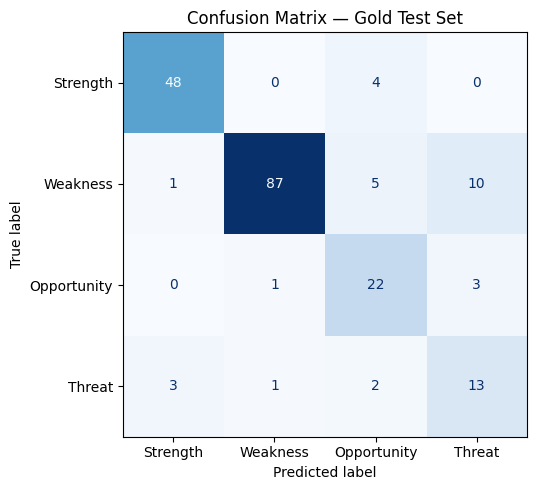

Row-normalised (recall per true class):
true/pred        Strength     Weakness  Opportunity       Threat
Strength             0.92         0.00         0.08         0.00
Weakness             0.01         0.84         0.05         0.10
Opportunity          0.00         0.04         0.85         0.12
Threat               0.16         0.05         0.11         0.68


In [28]:
cm = confusion_matrix(
    human_test["manual_swot"],
    pred_labels,
    labels=SWOT_LABELS
)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=SWOT_LABELS).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("Confusion Matrix — Gold Test Set")
plt.tight_layout()
plt.savefig("/kaggle/working/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()
print("Row-normalised (recall per true class):")
cm_norm = cm / np.clip(cm.sum(axis=1, keepdims=True), 1, None)
print(f"{'true/pred':12}" + "".join(f"{l:>13}" for l in SWOT_LABELS))
for i, lab in enumerate(SWOT_LABELS):
    print(f"{lab:12}" + "".join(f"{cm_norm[i, j]:>13.2f}" for j in range(len(SWOT_LABELS))))


In [29]:
errors_df = pd.DataFrame({
    "text": human_test["text_clean"].astype(str).to_numpy(),
    "true": human_test["manual_swot"].to_numpy(),
    "predicted": pred_labels
})
errors_df = errors_df[errors_df["true"] != errors_df["predicted"]].copy()
print(f"Misclassified: {len(errors_df)}/{len(human_test)}")
if len(errors_df):
    print((errors_df["true"] + " -> " + errors_df["predicted"]).value_counts())
    display(errors_df.head(15))


Misclassified: 30/200
Weakness -> Threat         10
Weakness -> Opportunity     5
Strength -> Opportunity     4
Threat -> Strength          3
Opportunity -> Threat       3
Threat -> Opportunity       2
Weakness -> Strength        1
Threat -> Weakness          1
Opportunity -> Weakness     1
Name: count, dtype: int64


,text,true,predicted
0,paying 24 dollars a month and cant even log on...,Weakness,Threat
4,plz make app to purchase the plan with upi,Opportunity,Threat
8,not all shows and movies are available,Weakness,Opportunity
18,peacocks subscription is affordable and both e...,Threat,Strength
36,8 minutes to load a simple app and play any ki...,Weakness,Strength
44,they took away the traveling option,Weakness,Threat
53,today again the payment is being asked to pay,Weakness,Threat
62,uninstalling netflix right now,Threat,Weakness
63,it will let you dowload videos if your ofline ...,Strength,Opportunity
67,"in order to watch netflix while travelling, if...",Weakness,Opportunity


## 14. Explainable AI


In [30]:
@torch.inference_mode()
def predict_logits(texts, batch_size=32):
    final_model.eval()
    device = next(final_model.parameters()).device
    outputs = []

    for start in range(0, len(texts), batch_size):
        batch = [str(t) for t in texts[start:start + batch_size]]
        encoded = final_tokenizer(
            batch,
            padding=True,
            truncation=True,
            max_length=MAX_LENGTH,
            return_tensors="pt"
        ).to(device)

        logits = final_model(**encoded).logits
        outputs.append(logits.float().cpu().numpy())

    return np.vstack(outputs)


def explain_occlusion(text, label):
    words = str(text).split()
    if len(words) < 2:
        return None
    target = SWOT_LABELS.index(label)
    altered = [" ".join(words[:j] + words[j + 1:]) for j in range(len(words))]
    scores = predict_logits([text] + altered)[:, target]
    return {"words": words, "label": label, "base_logit": float(scores[0]),
            "contributions": scores[0] - scores[1:]}

def plot_attribution(text, label, ax, limit=12):
    result = explain_occlusion(text, label)
    if result is None:
        ax.axis("off")
        return
    values = result["contributions"]
    chosen = sorted(np.argsort(-np.abs(values))[:limit])
    words = [f"{j + 1}. {result['words'][j]}" for j in chosen]
    weights = values[chosen]
    ax.barh(words[::-1], weights[::-1],
            color=["#247a50" if v > 0 else "#bd4a40" for v in weights[::-1]])
    ax.axvline(0, color="black", linewidth=0.7)
    ax.set_title(f"{label}  |  {str(text)[:80]}", fontsize=10, loc="left")
    ax.set_xlabel("Original class logit - logit without word")
    ax.spines[["top", "right"]].set_visible(False)

real_examples = {}
for category in SWOT_LABELS:
    options = [
        i for i, (gold, pred) in enumerate(zip(human_test["manual_swot"], pred_labels))
        if gold == category and pred == category
        and 5 <= len(str(human_test.iloc[i]["text_clean"]).split()) <= 24
    ]
    if options:
        selected = min(options, key=lambda i: (
            abs(len(str(human_test.iloc[i]["text_clean"]).split()) - 12), i
        ))
        real_examples[category] = str(human_test.iloc[selected]["text_clean"])


### 14.1 Word occlusion


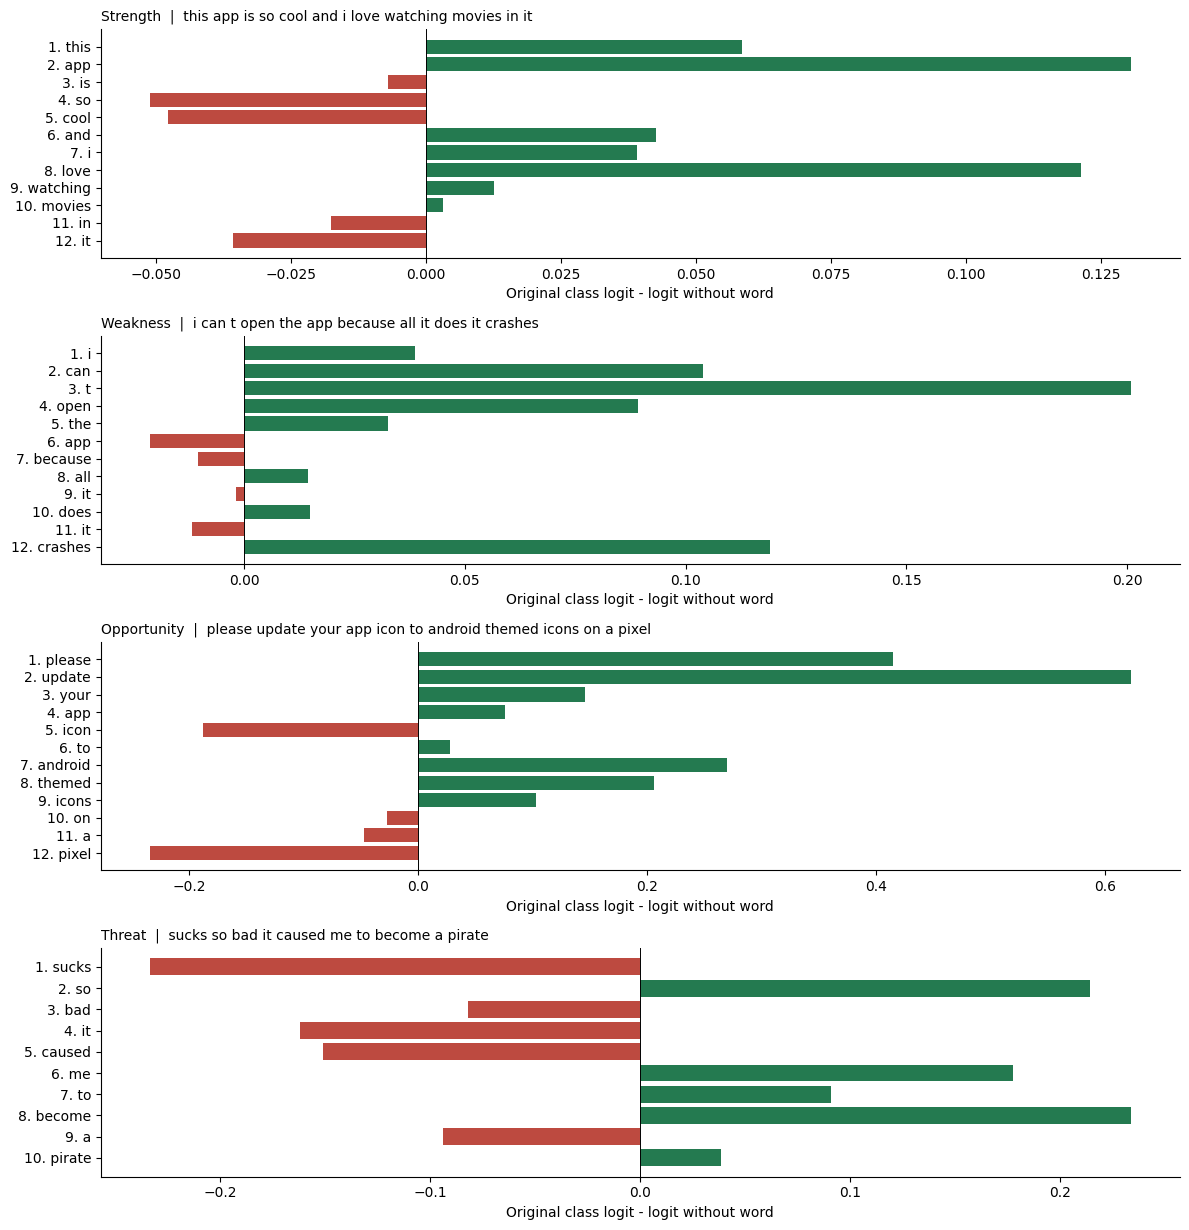

In [31]:
if real_examples:
    fig, axes = plt.subplots(len(real_examples), 1,
                             figsize=(12, 3.1 * len(real_examples)), squeeze=False)
    for ax, (category, text) in zip(axes.ravel(), real_examples.items()):
        plot_attribution(text, label=category, ax=ax)
    plt.tight_layout()
    plt.savefig("/kaggle/working/fig_token_attribution.png", dpi=160, bbox_inches="tight")
    plt.show()


### 14.2 SHAP


In [32]:
if "Strength" in real_examples:
    shap_text = real_examples["Strength"]
    shap_explainer = shap.Explainer(
        predict_logits, shap.maskers.Text(r"\W+"),
        output_names=SWOT_LABELS, algorithm="partition"
    )
    shap_values = shap_explainer([shap_text], max_evals=120)
    print("SHAP local example: Strength |", shap_text)
    shap.plots.text(shap_values[0, :, SWOT_LABELS.index("Strength")])


SHAP local example: Strength | this app is so cool and i love watching movies in it


### 14.3 LIME


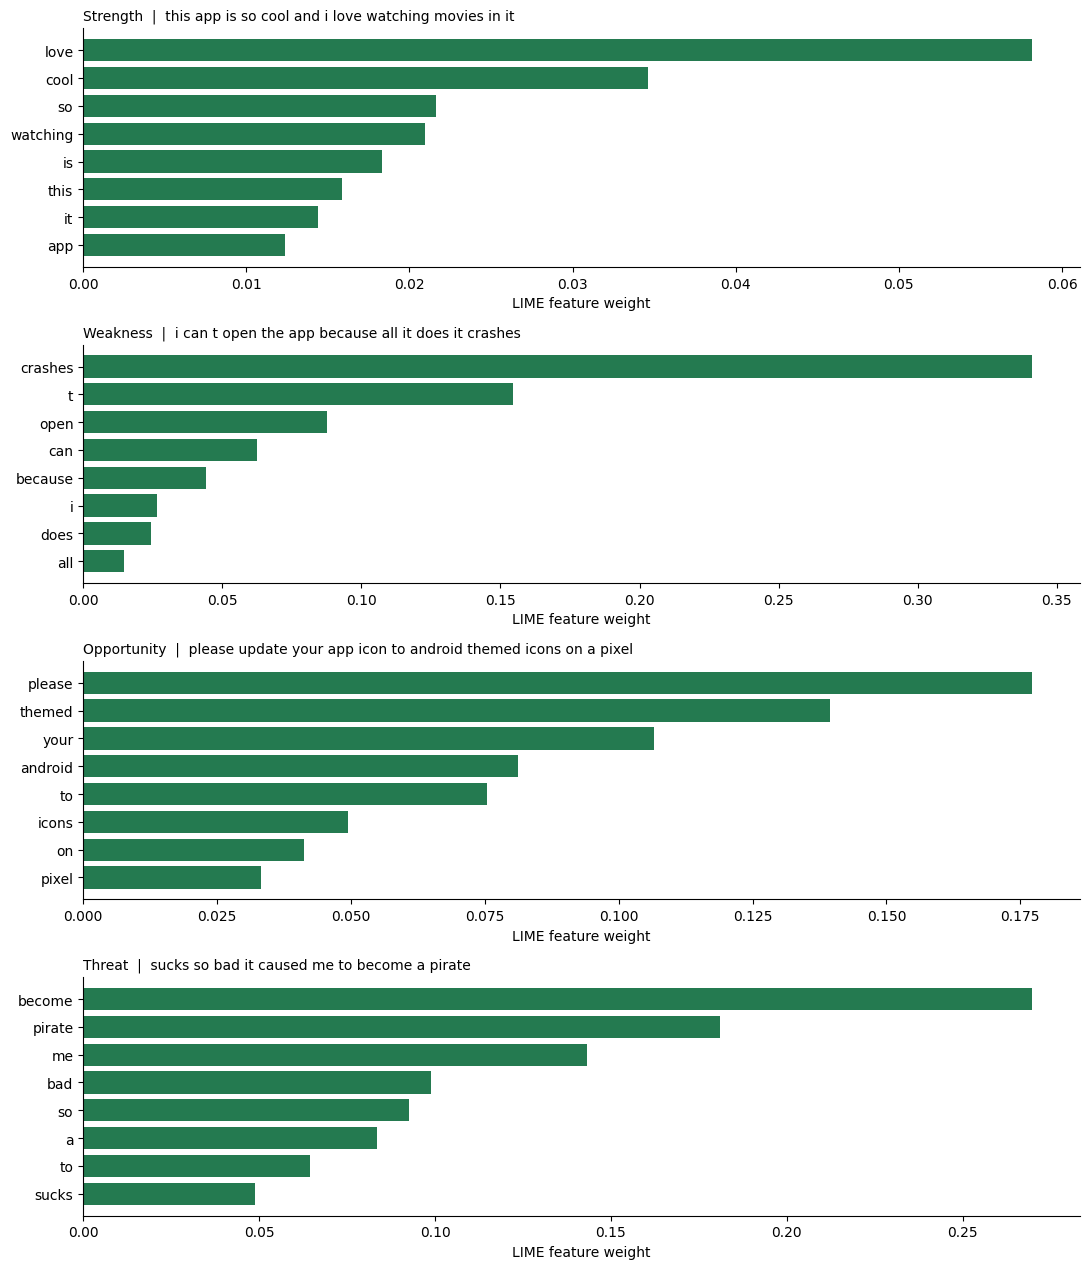

In [33]:
def lime_binary_probs(texts, class_index):
    probs = softmax(predict_logits(list(texts), batch_size=64), axis=1)
    positive = probs[:, class_index]
    return np.column_stack([1 - positive, positive])

if real_examples:
    fig, axes = plt.subplots(len(real_examples), 1,
                             figsize=(11, 3.2 * len(real_examples)), squeeze=False)
    for ax, (category, text) in zip(axes.ravel(), real_examples.items()):
        class_index = SWOT_LABELS.index(category)
        explainer = LimeTextExplainer(class_names=["Other", category], random_state=SEED)
        explanation = explainer.explain_instance(
            text, lambda samples: lime_binary_probs(samples, class_index),
            labels=[1], num_features=8, num_samples=500)
        items = sorted(explanation.as_list(label=1), key=lambda pair: pair[1])
        ax.barh([x[0] for x in items], [x[1] for x in items],
                color=["#247a50" if x[1] > 0 else "#bd4a40" for x in items])
        ax.axvline(0, color="black", lw=0.7)
        ax.set_title(f"{category}  |  {text[:75]}", fontsize=10, loc="left")
        ax.set_xlabel("LIME feature weight")
        ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.savefig("/kaggle/working/fig_lime.png", dpi=160, bbox_inches="tight")
    plt.show()


### 14.4 Integrated Gradients and Word Occlusion


Strength delta: 0.0000
Weakness delta: 0.0000
Opportunity delta: 0.0000
Threat delta: 0.0002


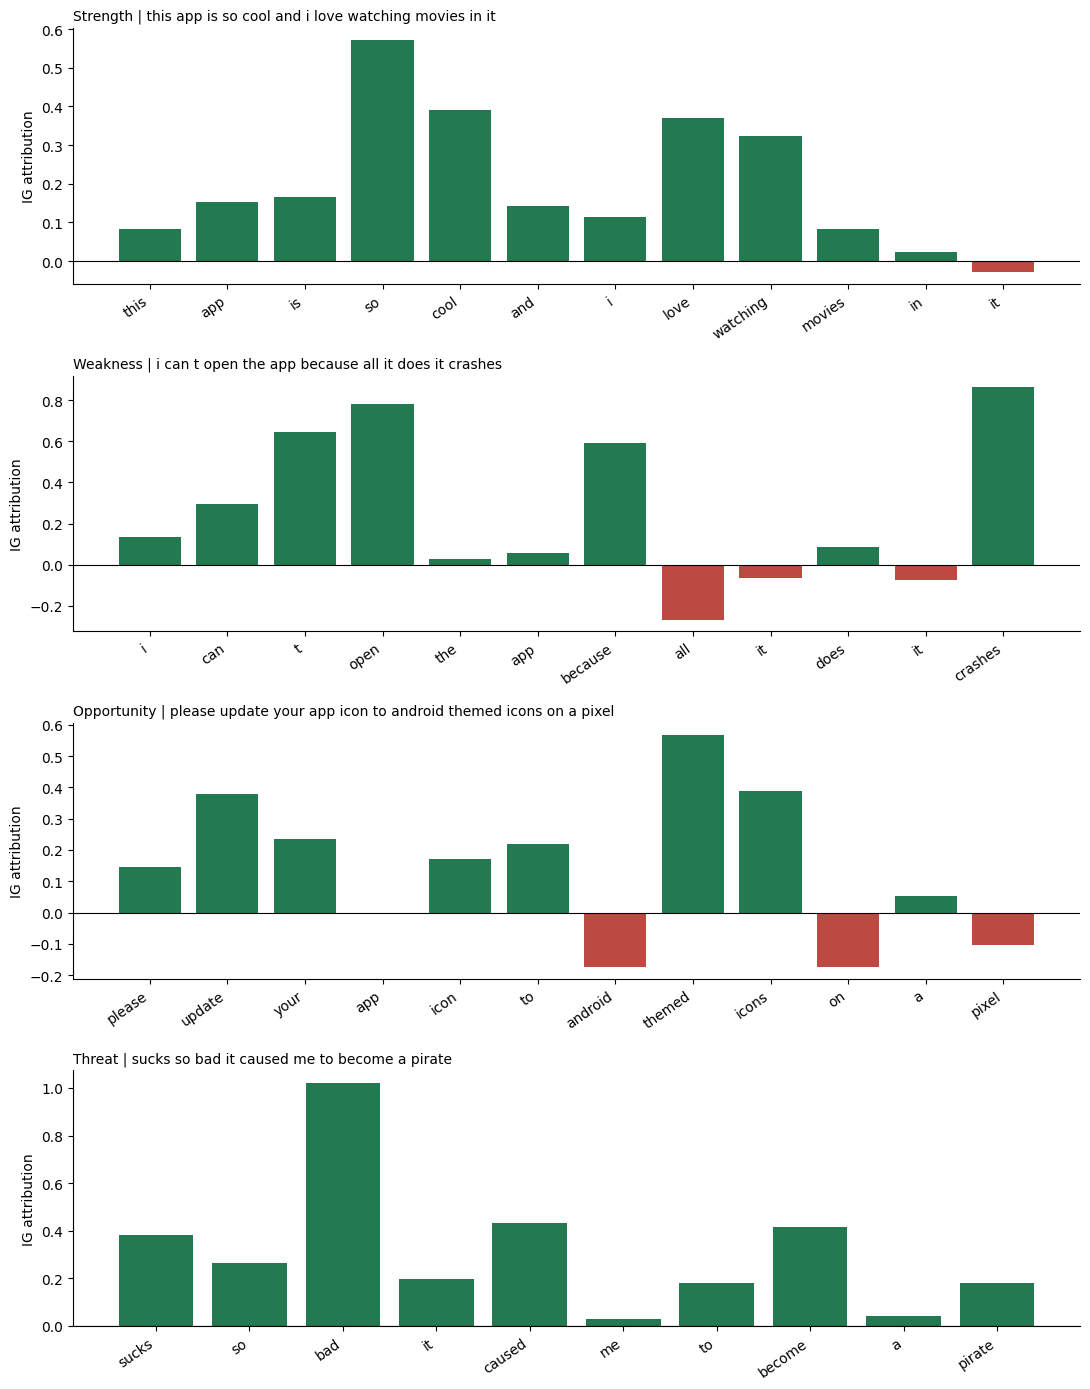

In [34]:
final_model.float()
final_model.eval()
device = next(final_model.parameters()).device

def forward_logits(input_ids, attention_mask):
    return final_model(
        input_ids=input_ids,
        attention_mask=attention_mask
    ).logits

ig = LayerIntegratedGradients(
    forward_logits,
    final_model.get_input_embeddings()
)

def ig_word_importance(text, label):
    text = str(text)
    matches = list(re.finditer(r"\S+", text))
    words = [m.group() for m in matches]

    encoded = final_tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH,
        return_offsets_mapping=True,
        return_special_tokens_mask=True
    )

    offsets = encoded["offset_mapping"][0].tolist()
    special = encoded["special_tokens_mask"].to(device).bool()

    ids = encoded["input_ids"].to(device)
    attention = encoded["attention_mask"].to(device)


    baseline = ids.clone()
    baseline[~special] = final_tokenizer.mask_token_id

    target = SWOT_LABELS.index(label)

    attributions, delta = ig.attribute(
        inputs=ids,
        baselines=baseline,
        additional_forward_args=(attention,),
        target=target,
        n_steps=256,
        method="gausslegendre",
        internal_batch_size=2,
        return_convergence_delta=True
    )

    token_scores = (
        attributions.sum(dim=-1)
        .squeeze(0).detach().cpu().numpy()
    )

    word_scores = np.zeros(len(words))

    for (start, end), value in zip(offsets, token_scores):
        if end <= start:
            continue

        for j, match in enumerate(matches):
            if match.start() < end and start < match.end():
                word_scores[j] += value
                break

    return words, word_scores, abs(float(delta.item()))


examples = real_examples.copy()


if not examples:
    raise ValueError("No correctly classified test examples for Integrated Gradients.")

fig, axes = plt.subplots(
    len(examples), 1,
    figsize=(11, 3.5 * len(examples)),
    squeeze=False
)

for ax, (category, text) in zip(axes.ravel(), examples.items()):
    words, scores, delta = ig_word_importance(text, category)

    positions = np.arange(len(words))

    ax.bar(
        positions,
        scores,
        color=[
            "#247a50" if value >= 0 else "#bd4a40"
            for value in scores
        ]
    )

    ax.set_xticks(positions)
    ax.set_xticklabels(words, rotation=35, ha="right")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f"{category} | {text}", fontsize=10, loc="left")
    ax.set_ylabel("IG attribution")
    ax.spines[["top", "right"]].set_visible(False)

    print(f"{category} delta: {delta:.4f}")

plt.tight_layout()
plt.savefig(
    "/kaggle/working/fig_integrated_gradients.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()


Integrated Gradients: Deletion AUC = 0.379, Insertion AUC = 0.801
Occlusion: Deletion AUC = 0.416, Insertion AUC = 0.786
Random: Deletion AUC = 0.598, Insertion AUC = 0.540


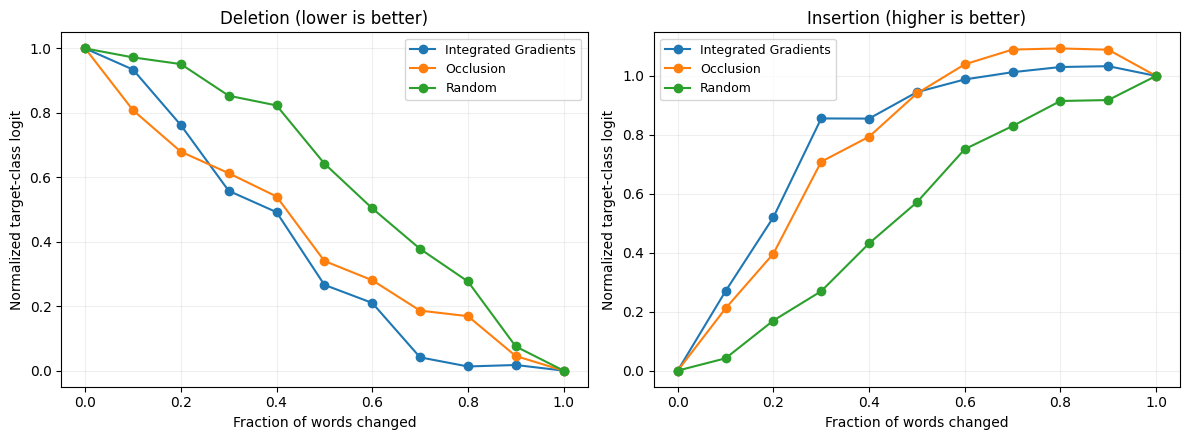


Exploratory comparison on 11 short, correctly classified test segments.


In [35]:
STEPS = 10
fractions = np.linspace(0, 1, STEPS + 1)
rng_faith = np.random.RandomState(SEED)

def faithfulness_curves(words, target, order, empty_score, full_score):
    removed = []
    inserted = []
    n = len(words)

    for fraction in fractions:
        indices = set(order[:int(round(fraction * n))])

        removed.append(
            " ".join(w for j, w in enumerate(words) if j not in indices) or " "
        )
        inserted.append(
            " ".join(w for j, w in enumerate(words) if j in indices) or " "
        )

    raw = predict_logits(removed + inserted)[:, target]
    scale = full_score - empty_score

    deletion = (raw[:len(fractions)] - empty_score) / scale
    insertion = (raw[len(fractions):] - empty_score) / scale

    return deletion, insertion


true_labels = human_test["manual_swot"].tolist()
predicted_labels = list(pred_labels)

faith_indices = [
    i for i, (gold, predicted) in enumerate(
        zip(true_labels, predicted_labels)
    )
    if gold == predicted
    and 5 <= len(str(human_test.iloc[i]["text_clean"]).split()) <= 18
]


faith_indices = [
    i
    for category in SWOT_LABELS
    for i in [j for j in faith_indices if true_labels[j] == category][:3]
]

curves = {
    name: {"deletion": [], "insertion": []}
    for name in ["Integrated Gradients", "Occlusion", "Random"]
}

usable = 0
empty_logits = predict_logits([" "])[0]

for i in faith_indices:
    text = str(human_test.iloc[i]["text_clean"])
    category = true_labels[i]
    target = SWOT_LABELS.index(category)


    words, importance_ig, delta = ig_word_importance(text, category)

    if words is None or len(words) < 2:
        continue

    full_score = float(predict_logits([text])[0, target])
    empty_score = float(empty_logits[target])

    if full_score - empty_score <= 0.5:
        continue


    oc = explain_occlusion(text, category)

    if oc is None:
        continue

    importance_oc = oc["contributions"]

    assert len(words) == len(importance_ig) == len(importance_oc)

    orders = {
        "Integrated Gradients": np.argsort(-importance_ig),
        "Occlusion": np.argsort(-importance_oc)
    }

    for name, order in orders.items():
        deletion, insertion = faithfulness_curves(
            words, target, order, empty_score, full_score
        )

        curves[name]["deletion"].append(deletion)
        curves[name]["insertion"].append(insertion)


    random_del = []
    random_ins = []

    for _ in range(5):
        order = rng_faith.permutation(len(words))

        deletion, insertion = faithfulness_curves(
            words, target, order, empty_score, full_score
        )

        random_del.append(deletion)
        random_ins.append(insertion)

    curves["Random"]["deletion"].append(
        np.mean(random_del, axis=0)
    )
    curves["Random"]["insertion"].append(
        np.mean(random_ins, axis=0)
    )

    usable += 1
if usable > 0:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

    for name, values in curves.items():
        deletion = np.mean(values["deletion"], axis=0)
        insertion = np.mean(values["insertion"], axis=0)

        axes[0].plot(fractions, deletion, marker="o", label=name)
        axes[1].plot(fractions, insertion, marker="o", label=name)

        deletion_auc = trapezoid(deletion, fractions)
        insertion_auc = trapezoid(insertion, fractions)

        print(
            f"{name}: "
            f"Deletion AUC = {deletion_auc:.3f}, "
            f"Insertion AUC = {insertion_auc:.3f}"
        )

    axes[0].set_title("Deletion (lower is better)")
    axes[1].set_title("Insertion (higher is better)")

    for ax in axes:
        ax.set_xlabel("Fraction of words changed")
        ax.set_ylabel("Normalized target-class logit")
        ax.grid(alpha=0.2)
        ax.legend(fontsize=9)

    plt.tight_layout()

    plt.savefig(
        "/kaggle/working/fig_faithfulness.png",
        dpi=160,
        bbox_inches="tight"
    )

    plt.show()

    print(f"\nExploratory comparison on {usable} short, correctly classified test segments.")

else:
    print("No suitable test segments for faithfulness evaluation.")


### 14.5 Word Clouds


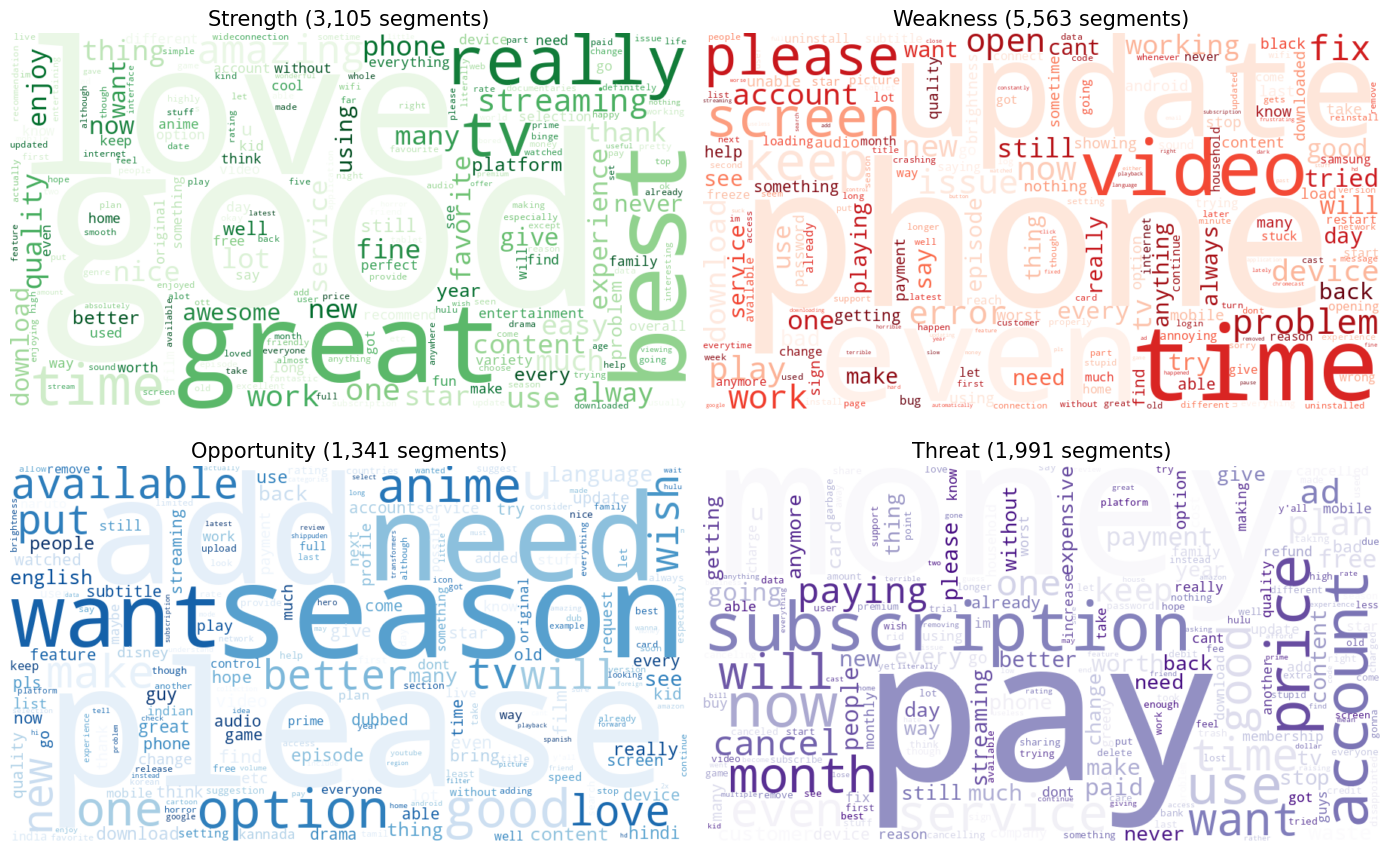

In [36]:
CLOUD_SAMPLE_SIZE = 12000

cloud_df = segments_df[["text_clean"]].dropna().copy()
cloud_df["text_clean"] = cloud_df["text_clean"].astype(str).str.strip()
cloud_df = cloud_df.loc[cloud_df["text_clean"].str.len() >= 15]

cloud_df = cloud_df.sample(
    n=min(CLOUD_SAMPLE_SIZE, len(cloud_df)),
    random_state=SEED
).reset_index(drop=True)

cloud_pred = predict_proba(
    cloud_df["text_clean"].tolist(),
    batch_size=16
)
cloud_df["swot"] = [SWOT_LABELS[i] for i in cloud_pred.argmax(axis=1)]

colors = {
    "Strength": "Greens",
    "Weakness": "Reds",
    "Opportunity": "Blues",
    "Threat": "Purples"
}


stop_words = set(STOPWORDS) | {
    "netflix", "app", "apps",
    "movie", "movies",
    "show", "shows",
    "watch", "watching",
    "series"
}

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, category in zip(axes.flat, SWOT_LABELS):
    texts = cloud_df.loc[cloud_df["swot"] == category, "text_clean"]
    combined_text = " ".join(texts)

    if combined_text.strip():
        cloud = WordCloud(
            width=900,
            height=500,
            background_color="white",
            colormap=colors[category],
            stopwords=stop_words,
            max_words=220,
            relative_scaling=0.5,
            prefer_horizontal=0.9,
            margin=1,
            collocations=False,
            random_state=SEED
        ).generate(combined_text)

        ax.imshow(cloud, interpolation="bilinear")

    ax.set_title(f"{category} ({len(texts):,} segments)", fontsize=15)
    ax.axis("off")

plt.tight_layout()
plt.savefig(
    "/kaggle/working/fig_swot_wordclouds.png",
    dpi=180,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()


## 15. Final Checks and Outputs


In [37]:
required_files = [
    Path(FINAL_MODEL_DIR) / "config.json",
    Path(FINAL_MODEL_DIR) / "model.safetensors",
    Path(FINAL_MODEL_DIR) / "test_metrics.json",
    Path(FINAL_MODEL_DIR) / "inference_params.json",
    OUTPUT_DIR / "cv_fold_results.csv",
    OUTPUT_DIR / "cv_oof_predictions.csv",
    OUTPUT_DIR / "cv_selection.json",
    OUTPUT_DIR / "cv_fold_info.csv",
    OUTPUT_DIR / "training_config.json",
    OUTPUT_DIR / "test_predictions.csv",
    OUTPUT_DIR / "test_confidence_intervals.csv",
    Path("/kaggle/working/fig_cv_train_validation_loss.png"),
    Path("/kaggle/working/confusion_matrix.png"),
    Path("/kaggle/working/fig_swot_wordclouds.png"),
]
if usable > 0:
    required_files.append(Path("/kaggle/working/fig_faithfulness.png"))
missing = [str(path) for path in required_files if not path.is_file()]
if missing:
    raise FileNotFoundError(f"Missing final artifacts: {missing}")
assert df_raw["date"].ge(SOURCE_START_DATE).all()
assert cv_fold_summary["fold"].nunique() == CV_FOLDS
assert selected_epochs == int(np.median(cv_fold_summary["best_epoch"]))
assert len(oof_rows) == len(human_development)
assert len({row["development_index"] for row in oof_rows}) == len(human_development)
assert isinstance(selected_epochs, int)
assert 0 < selected_final_steps <= planned_final_steps
assert 1 <= selected_epochs <= MAX_CV_EPOCHS
assert inference_params["test_used_for_classifier_training"] is False
assert inference_params["test_used_for_checkpoint_selection"] is False
print("Model:", FINAL_MODEL_DIR)
print("Source period:", str(df_raw["date"].min().date()), "to", str(df_raw["date"].max().date()))
print("Selected stage:", selected_stage)
print(f"CV Macro F1 at fold-best checkpoints: {cv_best_macro_f1:.4f} (+/- {cv_best_macro_std:.4f} SD)")
print(f"Selected LR: {selected_lr:g}; epochs: {selected_epochs}; steps: {selected_final_steps}")
print(f"Final development TRAIN F1 (in-sample): {selected_train_scores['macro_f1']:.4f}")
print(f"Test Accuracy: {accuracy:.4f} | Macro F1: {macro_f1:.4f}")
print("Verified artifacts:", len(required_files))

import importlib.metadata
versions = {name: importlib.metadata.version(name) for name in [
    "torch", "transformers", "datasets", "accelerate", "numpy", "pandas", "scikit-learn"
]}
(OUTPUT_DIR / "runtime_versions.json").write_text(json.dumps(versions, indent=2), encoding="utf-8")


Model: /kaggle/working/swot_roberta_base_regularized/best_model_verified
Source period: 2020-01-01 to 2026-11-13
Selected stage: RoBERTa-base with 6 frozen layers and grouped-CV early stopping
CV Macro F1 at fold-best checkpoints: 0.7613 (+/- 0.0287 SD)
Selected LR: 1e-05; epochs: 2; steps: 378
Final development TRAIN F1 (in-sample): 0.8258
Test Accuracy: 0.8500 | Macro F1: 0.7882
Verified artifacts: 15


174